# Porto — bổ sung chuyến để tăng độ phủ trên vùng C 8×8 km

Giữ nguyên bbox, snapshot graph và ngưỡng QA của lần matching 9.501 chuyến. Tái sử dụng
trực tiếp các quan sát đạt QA đã lưu; chỉ matching chuyến mới. Mục tiêu là tiến gần
toàn bộ **15.882 cạnh có chiều dài dương trong vùng**, không đổi vùng hoặc tạo dữ liệu giả.
100% là mục tiêu, không phải kết quả được bảo đảm: dataset taxi có thể không quan sát
một số đường, và OSM năm 2026 có thể khác GPS năm 2013.

**Giữ nguyên:** cleaning/timestamp gốc, Leuven HMM có hướng, partial-edge, QA và graph.
**Điều chỉnh so với đề cương PDF:** thêm chọn mẫu thích nghi theo độ phủ; CPU theo batch;
không ép tỷ lệ 70/30 cho mẫu bổ sung vì đây là mẫu chủ đích tìm cạnh còn thiếu.
**Hoãn:** train mô hình, validation/test, nhãn giảm tốc, web/API và demo định tuyến.

Quét CSV để tìm ứng viên khác với matching toàn bộ dataset. Chỉ parse GPS của các chuyến
metadata hợp lệ trong giai đoạn train, đọc theo chunk và lưu shard Parquet. Các ô lưới
chỉ giúp xếp hạng ứng viên; **không phải map matching và không được tính là cạnh đã phủ**.
Chỉ chuỗi cạnh từ HMM vượt qua QA mới làm tăng coverage thực tế.

> **Bố cục repo:** notebook đã được chuyển vào thư mục theo bước và tự tìm thư mục gốc. Các output đang hiển thị được giữ từ lượt thực thi trước khi sắp xếp đường dẫn; không chạy lại matching/train trong bước sắp xếp này. Run All tiếp theo sẽ dùng đường dẫn mới và cache hợp lệ.

## A. Cấu hình

Cấu hình hiện tại gồm 5 đợt × 5.000 chuyến bổ sung ngoài baseline 9.501 chuyến.
Ba đợt đầu tái sử dụng cache; đợt 4–5 bổ sung 10.000 chuyến mới so với lượt hoàn tất trước.
Giữ nguyên `max_additional_trips_per_round`, seed, vùng, graph và QA để tiếp tục đúng cache.
Số cạnh tăng thêm chỉ được xác nhận sau matching và QA, không bằng số chuyến được chọn.


In [1]:
from pathlib import Path
import os
# Locate the repository from either its root or a notebook subfolder.
_current_dir = Path.cwd().resolve()
ROOT = next((candidate for candidate in (_current_dir, *_current_dir.parents)
             if (candidate / "notebooks").is_dir() and (candidate / "requirements").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the cloned repository (notebooks/ and requirements/ must exist).")
CFG={'region_name': 'C_8km',
 'nominal_side_km': 8.0,
 'region_center_source': 'Center of C_4km; expanded in EPSG:32629 and enclosed by WGS84 bbox',
 'bbox': [-8.654504338104756, 41.12745663346633, -8.558716252527459, 41.199844416439696],
 'cache_dir': 'cache/region_coverage_expansion',
 'output_dir': 'outputs/region_coverage_expansion',
 'csv_dir': 'outputs/csv',
 'metric_crs': 'EPSG:32629',
 'timezone': 'Europe/Lisbon',
 'graph_buffer_m': 200,
 'seed': 313,
 'matching_workers': 6,
 'gps_interval_s': 15,
 'min_points': 4,
 'max_points_per_subtrajectory': 180,
 'matching_batch_size': 25,
 'candidate_radius_m': 60,
 'gps_error_m': 25,
 'hmm_lattice_width': 12,
 'microedge_max_m': 60,
 'max_match_error_m': 45,
 'max_mean_match_error_m': 30,
 'min_matched_point_ratio': 0.7,
 'min_retained_interval_ratio': 0.6,
 'max_matched_speed_kmh': 140,
 'max_detour_ratio': 5.0,
 'detour_floor_m': 40,
 'backward_jitter_m': 5,
 'time_bin_hours': 1,
 'coverage_min_trips': 5,
 'coverage_min_taxis': 3,
 'coverage_min_days': 3,
 'force_rematch': False,
 'cpu_threads': 4,
 'data_path': 'data/train.csv',
 'zip_member': None,
 'baseline_run': 'outputs/region_pilot/8946a3b89ff42fa9ba5c',
 'chunk_size': 25000,
 'candidate_shard_points': 50000,
 'selection_grid_m': 200,
 'candidate_cell_buffer_m': 30,
 'max_additional_trips_per_round': 5000,
 'max_rounds': 5,
 'target_edge_coverage': 1.0,
 'min_new_edges_stop': 10,
 'max_departure_day_share': 0.08,
 'max_taxi_share': 0.025,
 'missing_edge_boost': 5.0,
 'force_scan': False,
 'force_selection': False,
 'verify_full_hash': False}
for name in ["OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS"]:
    os.environ[name]=str(CFG["cpu_threads"])

In [2]:
# Nếu thiếu dependencies, bỏ dấu # và chạy một lần trong đúng kernel:
# %pip install -r "{ROOT / 'requirements/requirements_region_pilot.txt'}"

In [3]:
import ast, contextlib, hashlib, importlib.util, importlib.metadata, inspect, json, math, time, sys
from datetime import datetime, timezone
import logging
REQUIRED = {"numpy":"numpy", "pandas":"pandas", "pyarrow":"pyarrow", "shapely":"shapely",
            "geopandas":"geopandas", "pyproj":"pyproj", "osmnx":"osmnx", "networkx":"networkx",
            "matplotlib":"matplotlib", "psutil":"psutil", "leuvenmapmatching":"leuvenmapmatching", "rtree":"rtree", "joblib":"joblib"}
missing = [dist for mod, dist in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    raise RuntimeError("Thiếu dependencies: " + ", ".join(missing) + "; cài ở cell hướng dẫn.")
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import psutil
import shapely
from shapely.geometry import Point, LineString, box
from shapely.ops import substring
from pyproj import Transformer
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from IPython.display import display, Markdown
logging.getLogger("be.kuleuven.cs.dtai.mapmatching").setLevel(logging.ERROR)
VERSIONS = {dist:importlib.metadata.version(dist) for dist in REQUIRED.values()}
OPTIONAL = {name:(importlib.metadata.version(name) if importlib.util.find_spec(name) else "not installed") for name in ["fastmm","fmm"]}
display(pd.Series({**VERSIONS, **OPTIONAL}, name="version").to_frame())
print("Matcher: Leuven HMM. Không dùng nearest-edge thay map matching.")
print("FMM/fastmm không bắt buộc; API FMM chưa được xác minh trong môi trường này.")

def stable_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()

def file_hash(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda:handle.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def write_json(path,value):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+".tmp")
    payload=json.dumps(value,ensure_ascii=False,indent=2,default=str)
    # Windows readers or antivirus can briefly deny replacement of an open file.
    for attempt in range(10):
        try:
            temp.write_text(payload,encoding="utf-8")
            temp.replace(path)
            return
        except PermissionError:
            if attempt==9:
                raise
            time.sleep(min(.4,.025*(2**attempt)))

def csv_path(path):
    return ROOT/CFG["csv_dir"]/Path(path).resolve().relative_to((ROOT/"outputs").resolve()).with_suffix(".csv")

def write_table(frame,path,csv=False):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(".tmp.parquet")
    frame.to_parquet(temp,index=False); temp.replace(path)
    if csv:
        target=csv_path(path); target.parent.mkdir(parents=True,exist_ok=True)
        frame.to_csv(target,index=False,encoding="utf-8-sig")

def record_stage(name,status,detail):
    STAGES[name]={"status":status,"detail":str(detail)}
    write_json(RUN/"stage_status.json", STAGES)
    print(f"[{name}] {status}: {detail}")

@contextlib.contextmanager
def timed(name):
    before=time.perf_counter(); rss=psutil.Process().memory_info().rss/2**20
    try:
        yield
    finally:
        row={"stage":name,"seconds":time.perf_counter()-before,"rss_before_mb":rss,
             "rss_after_mb":psutil.Process().memory_info().rss/2**20}
        RUNTIME.append(row); write_json(RUN/"runtime.json",RUNTIME)
        print(f"{name}: {row['seconds']:.1f}s; RSS cuối bước={row['rss_after_mb']:.0f} MiB")

def save_figure(name):
    plt.tight_layout(); plt.savefig(FIGURES/(name+".png"),dpi=150,bbox_inches="tight")
    plt.show(); plt.close()


import sqlite3, zipfile, heapq
from pyproj import Geod
GEOD=Geod(ellps="WGS84")
BASE=ROOT/CFG["baseline_run"]
if not BASE.exists(): raise FileNotFoundError(f"Thiếu baseline {BASE}; chạy notebook matching trước.")
BASE_CFG=json.loads((BASE/"config.json").read_text(encoding="utf-8"))
BASE_SOURCE=json.loads((BASE/"data_source.json").read_text(encoding="utf-8"))
BASE_VERSIONS=json.loads((BASE/"environment.json").read_text(encoding="utf-8"))["packages"]
assert all(VERSIONS[k]==BASE_VERSIONS[k] for k in VERSIONS),"Phiên bản thư viện khác baseline; không gộp âm thầm."
EDA_RUN=Path(BASE_SOURCE["eda_run"])
if not EDA_RUN.exists():
    EDA_RUN=ROOT/"outputs/region_eda"/EDA_RUN.name
EDA_CONFIG=json.loads((EDA_RUN/"config.json").read_text(encoding="utf-8"))
EDA_KEYS=json.loads((EDA_RUN/"cache_keys.json").read_text(encoding="utf-8"))
DATA_PATH=ROOT/CFG["data_path"]
if not DATA_PATH.exists(): raise FileNotFoundError(f"Thiếu dữ liệu thật {DATA_PATH}; sửa CFG['data_path'].")
START=pd.Timestamp(BASE_SOURCE["study_start"]).tz_convert("UTC")
END=pd.Timestamp(BASE_SOURCE["study_end"]).tz_convert("UTC")
for key in ["gps_interval_s","min_trip_points","min_segment_points","max_gps_speed_kmh","broad_geo_bbox"]:
    CFG[key]=EDA_CONFIG[key]
NUMERIC_KEYS=["bbox","metric_crs","timezone","graph_buffer_m","gps_interval_s","min_points",
    "max_points_per_subtrajectory","candidate_radius_m","gps_error_m","hmm_lattice_width","microedge_max_m",
    "max_match_error_m","max_mean_match_error_m","min_matched_point_ratio","min_retained_interval_ratio",
    "max_matched_speed_kmh","max_detour_ratio","detour_floor_m","backward_jitter_m"]
assert all(CFG[k]==BASE_CFG[k] for k in NUMERIC_KEYS),"Để gộp kết quả cũ, phải giữ graph/vùng và QA như baseline."
assert CFG["max_rounds"]>=1 and CFG["max_additional_trips_per_round"]>=1
assert isinstance(CFG["time_bin_hours"],int) and CFG["time_bin_hours"]>=1 and 24%CFG["time_bin_hours"]==0
assert 0<CFG["target_edge_coverage"]<=1 and 0<CFG["max_departure_day_share"]<=1
PROJECT=Transformer.from_crs(4326,CFG["metric_crs"],always_xy=True)
UNPROJECT=Transformer.from_crs(CFG["metric_crs"],4326,always_xy=True)
STUDY_POLYGON=shapely.transform(box(*CFG["bbox"]),PROJECT.transform,interleaved=False)
BUFFER_POLYGON=STUDY_POLYGON.buffer(CFG["graph_buffer_m"])
CACHE=ROOT/CFG["cache_dir"];OUTPUT=ROOT/CFG["output_dir"]
CACHE.mkdir(parents=True,exist_ok=True)
NOTEBOOK_PATH=ROOT/"notebooks/03_region_coverage/porto_region_coverage_expansion.ipynb"
CODE_HASH=stable_hash([c["source"] for c in json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))["cells"] if c["cell_type"]=="code"])
BASE_FILES=["config.json","edges.parquet","region_matching_parts.parquet","matching_qa.parquet","selected_trips.parquet","edge_inside_offset_ranges.json"]
BASE_HASHES={name:file_hash(BASE/name) for name in BASE_FILES}
RUN_KEY=stable_hash([CFG,CODE_HASH,BASE_HASHES, VERSIONS])[:20]
EXP_RUN=RUN=OUTPUT/RUN_KEY;FIGURES=RUN/"figures";FIGURES.mkdir(parents=True,exist_ok=True)
RUNTIME=[];STAGES={}
write_json(RUN/"config.json",CFG)
write_json(RUN/"environment.json",{"python":sys.version,"packages":VERSIONS})
write_json(RUN/"baseline_provenance.json",{"baseline":str(BASE),"sha256":BASE_HASHES,"train_start":START,"train_end_exclusive":END})
print("Output:",RUN)
print("Chỉ bổ sung train:",START,"đến trước",END)

,version
numpy,2.1.3
pandas,2.3.2
pyarrow,23.0.1
shapely,2.2.0
geopandas,1.2.0
pyproj,3.8.0
osmnx,2.1.1
networkx,3.5
matplotlib,3.10.0
psutil,7.1.0


Matcher: Leuven HMM. Không dùng nearest-edge thay map matching.
FMM/fastmm không bắt buộc; API FMM chưa được xác minh trong môi trường này.
Output: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\region_coverage_expansion\a3bc4981c0524eb0f19f
Chỉ bổ sung train: 2013-06-30 23:00:00+00:00 đến trước 2013-08-04 23:00:00+00:00


## B. Giữ mạng đường và kiểm chứng nguồn baseline

Graph không tải lại và ID `(u,v,key)` không thay đổi. So sánh ngưỡng matching và QA
với baseline trước khi gộp. Quan sát cũ được giữ nguyên từng byte trong file gốc.
Cạnh chưa có taxi vẫn nằm trong graph, với trạng thái thiếu quan sát.

In [4]:
def offset_ranges_in_polygon(line,polygon):
    ranges=[]; offset=0.
    coords=list(line.coords)
    for a,b in zip(coords[:-1],coords[1:]):
        segment=LineString([a,b]); length=segment.length
        if length<=1e-9:
            continue
        intersection=segment.intersection(polygon)
        for piece in shapely.get_parts(intersection):
            if isinstance(piece,LineString) and piece.length>1e-8:
                left=segment.project(Point(piece.coords[0])); right=segment.project(Point(piece.coords[-1]))
                ranges.append((offset+min(left,right),offset+max(left,right)))
        offset+=length
    merged=[]
    for a,b in sorted(ranges):
        if merged and a<=merged[-1][1]+1e-7:
            merged[-1]=(merged[-1][0],max(b,merged[-1][1]))
        else:
            merged.append((float(a),float(b)))
    return merged

def scalar_attribute(value, default="unknown"):
    if isinstance(value, (list,tuple,set)):
        return "|".join(sorted(map(str,value)))
    return default if value is None else str(value)

def make_edge_table(graph):
    rows = []
    for u,v,key,data in sorted(graph.edges(keys=True,data=True),key=lambda e: (int(e[0]),int(e[1]),int(e[2]))):
        start = Point(graph.nodes[u]["x"],graph.nodes[u]["y"])
        end = Point(graph.nodes[v]["x"],graph.nodes[v]["y"])
        geometry = data.get("geometry",LineString([start,end]))
        if not isinstance(geometry,LineString) or geometry.length<=0:
            continue
        coordinates = []
        for coordinate in geometry.coords:
            if not coordinates or np.hypot(coordinate[0]-coordinates[-1][0],coordinate[1]-coordinates[-1][1])>1e-6:
                coordinates.append(coordinate)
        if len(coordinates)<2:
            continue
        geometry = LineString(coordinates)
        if Point(geometry.coords[-1]).distance(start) < Point(geometry.coords[0]).distance(start):
            geometry = LineString(list(geometry.coords)[::-1])
        if Point(geometry.coords[0]).distance(start)>2 or Point(geometry.coords[-1]).distance(end)>2:
            raise ValueError(f"Hình học cạnh {u}:{v}:{key} không khớp node endpoints.")
        rows.append({"edge_id": f"{u}:{v}:{key}","u":int(u),"v":int(v),"key":int(key),
                     "length_m":geometry.length,"road_class":scalar_attribute(data.get("highway")),
                     "maxspeed":scalar_attribute(data.get("maxspeed")),
                     "geometry":geometry,"x":geometry.centroid.x,"y":geometry.centroid.y,
                     "in_study":STUDY_POLYGON.covers(geometry)})
    edges = gpd.GeoDataFrame(rows,geometry="geometry",crs=graph.graph["crs"])
    edges["fmm_id"] = np.arange(1,len(edges)+1,dtype=np.int64)
    return edges
with timed("load_verified_baseline"):
    EDGES=gpd.read_parquet(BASE/"edges.parquet")
    GRAPH_HASH=str(EDGES.graph_hash.iloc[0])
    assert EDGES.graph_hash.nunique()==1 and EDGES.edge_id.is_unique
    ranges=json.loads((BASE/"edge_inside_offset_ranges.json").read_text(encoding="utf-8"))
    EDGES["inside_offset_ranges"]=[ranges[e] for e in EDGES.edge_id]
    REGION_EDGES=EDGES[EDGES.length_inside_m.gt(1e-8)].copy().reset_index(drop=True)
    BASE_PARTS=pd.read_parquet(BASE/"region_matching_parts.parquet")
    BASE_SELECTED=pd.read_parquet(BASE/"selected_trips.parquet")
    ALL_ORIGINAL_IDS=set(pd.read_parquet(EDA_RUN/"selected_trips.parquet",columns=["trip_id"]).trip_id.astype(str))
    BASE_COVERED=set(BASE_PARTS.edge_id)
    assert BASE_COVERED.issubset(set(REGION_EDGES.edge_id))
    assert BASE_PARTS.graph_hash.eq(GRAPH_HASH).all()
    assert BASE_SELECTED.trip_id.is_unique
    observed_summary=json.loads((BASE/"coverage_metrics.json").read_text(encoding="utf-8"))
    assert len(BASE_COVERED)==observed_summary["observed_edges_after_qa"]
    assert BASE_PARTS.trip_id.nunique()==observed_summary["trips_with_qa_observations_inside"]
    write_json(RUN/"graph_reference.json",{"graph_hash":GRAPH_HASH,"edges_path":str(BASE/"edges.parquet"),
        "edge_sha256":BASE_HASHES["edges.parquet"],"n_region_edges":len(REGION_EDGES),"baseline_observed_edges":len(BASE_COVERED)})
    display(pd.DataFrame([{"scope":"Baseline mẫu EDA","selected_trips":len(BASE_SELECTED),"observed_edges":len(BASE_COVERED),
        "region_edges":len(REGION_EDGES),"coverage":len(BASE_COVERED)/len(REGION_EDGES)}]))

,scope,selected_trips,observed_edges,region_edges,coverage
0,Baseline mẫu EDA,9501,7539,15882,0.474688


load_verified_baseline: 0.8s; RSS cuối bước=572 MiB


## C. Quét ứng viên trong train và cache riêng

Tái sử dụng SQLite metadata đã loại trùng của EDA, kiểm tra SHA-256 nội dung CSV
(ZIP được giải nén dạng stream). Chỉ GPS của các dòng train hợp lệ mới được parse.
Loại tất cả TRIP_ID thuộc mẫu 10.000 ban đầu, không chỉ 9.501 chuyến trong vùng.
Chuyến vượt qua ranh giới kết thúc train bị loại toàn chuyến khỏi mẫu bổ sung.

Cleaning dùng đúng hàm của EDA: `timestamp = trip_timestamp + 15 × original_index`,
tách nhảy GPS/khoảng trống, giữ điểm đứng yên. Sau cleaning chỉ lưu context trong
vùng đệm; mất liên tục vẫn được thể hiện bằng original_index và segment_id.
Cache scan không phụ thuộc số đợt hay ngân sách matching; tăng ngân sách không quét lại CSV.
Sau lần băm toàn bộ đầu tiên, fingerprint đường dẫn/kích thước/mtime dùng lại SHA-256
đã xác minh. Đặt `verify_full_hash=True` để buộc đọc và kiểm tra lại toàn bộ nội dung.

?ng vi?n ph?i c? ?t nh?t m?t GPS sau cleaning trong bbox, k? c? chuy?n b?t ??u ngo?i v?ng. Chuy?n ch? c?t qua g?c v?ng gi?a hai GPS m? kh?ng c? ?i?m trong bbox ch?a thu?c pool n?y; ??y c?ng l? gi?i h?n khi h??ng t?i to?n b? c?nh.

In [5]:
def clean_gps(polyline,trip_timestamp,trip_id="trip",taxi_id="taxi",missing_flag=False):
    stats={"raw_points":0,"kept_points":0,"invalid_coordinates":0,"outside_broad_geography":0,
           "outside_study_time":0,"jump_links":0,"short_segment_points":0,"n_segments":0,
           "raw_duration_s":0.,"retained_duration_s":0.,"gps_distance_m":0.,"reason":"retained"}
    if str(missing_flag).strip().lower() in ["true","1"]:
        stats["reason"]="missing_data_true"; return [],stats
    try:
        coordinates=json.loads(polyline)
    except (ValueError,TypeError):
        stats["reason"]="invalid_json"; return [],stats
    if not isinstance(coordinates,list):
        stats["reason"]="invalid_polyline"; return [],stats
    stats["raw_points"]=len(coordinates)
    stats["raw_duration_s"]=max(0,len(coordinates)-1)*CFG["gps_interval_s"]
    if len(coordinates)<CFG["min_trip_points"]:
        stats["reason"]="empty_or_short_trip"; return [],stats
    west,south,east,north=CFG["broad_geo_bbox"]
    valid=[]
    for original_index,pair in enumerate(coordinates):
        timestamp=int(trip_timestamp)+CFG["gps_interval_s"]*original_index
        try:
            if not isinstance(pair,(list,tuple)) or len(pair)!=2: raise ValueError("coordinate shape")
            lon,lat=map(float,pair)
            if not np.isfinite([lon,lat]).all() or not (-180<=lon<=180 and -90<=lat<=90): raise ValueError("coordinate range")
        except (TypeError,ValueError,OverflowError):
            stats["invalid_coordinates"]+=1; continue
        if not (west<=lon<=east and south<=lat<=north):
            stats["outside_broad_geography"]+=1; continue
        if not (START.timestamp()<=timestamp<END.timestamp()):
            stats["outside_study_time"]+=1; continue
        valid.append({"trip_id":str(trip_id),"taxi_id":str(taxi_id),"original_index":original_index,
                      "timestamp":timestamp,"lon":lon,"lat":lat})
    segments=[]; segment=[]
    for point in valid:
        if segment:
            previous=segment[-1]
            distance=GEOD.inv(previous["lon"],previous["lat"],point["lon"],point["lat"])[2]
            dt=point["timestamp"]-previous["timestamp"]
            discontinuity=point["original_index"]!=previous["original_index"]+1
            jumping=distance/dt*3.6>CFG["max_gps_speed_kmh"]
            if discontinuity or jumping:
                stats["jump_links"]+=int(jumping and not discontinuity)
                if len(segment)>=CFG["min_segment_points"]: segments.append(segment)
                else: stats["short_segment_points"]+=len(segment)
                segment=[]
        segment.append(point)
    if segment:
        if len(segment)>=CFG["min_segment_points"]: segments.append(segment)
        else: stats["short_segment_points"]+=len(segment)
    if sum(map(len,segments))<CFG["min_trip_points"]:
        stats["reason"]="too_few_retained_points"; return [],stats
    kept=[]
    for number,part in enumerate(segments):
        for point in part:
            point["segment_id"]=f"{trip_id}:seg{number}"
            point["is_original_start"]=point["original_index"]==0
            point["is_original_end"]=point["original_index"]==len(coordinates)-1
            kept.append(point)
        for left,right in zip(part[:-1],part[1:]):
            assert right["original_index"]==left["original_index"]+1
            stats["gps_distance_m"]+=GEOD.inv(left["lon"],left["lat"],right["lon"],right["lat"])[2]
            stats["retained_duration_s"]+=right["timestamp"]-left["timestamp"]
    stats["kept_points"]=len(kept); stats["n_segments"]=len(segments)
    return kept,stats
@contextlib.contextmanager
def input_stream(path,member=None):
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as archive:
            names=[n for n in archive.namelist() if Path(n).name.lower()=="train.csv"]
            chosen=member or (names[0] if len(names)==1 else None)
            if chosen not in archive.namelist(): raise ValueError("ZIP phải chứa train.csv duy nhất, hoặc đặt zip_member.")
            with archive.open(chosen) as stream: yield stream
    else:
        with Path(path).open("rb") as stream: yield stream

def content_hash(path,member=None):
    h=hashlib.sha256()
    with input_stream(path,member) as stream:
        for block in iter(lambda:stream.read(1024*1024),b""): h.update(block)
    return h.hexdigest()

def verified_source_hash():
    info=DATA_PATH.stat()
    fingerprint={"path":str(DATA_PATH.resolve()),"size":info.st_size,"mtime_ns":info.st_mtime_ns,"zip_member":CFG["zip_member"]}
    memo=CACHE/"source_fingerprints"/(stable_hash(fingerprint)+".json")
    reuse=memo.exists() and not CFG["verify_full_hash"]
    if reuse:
        cached=json.loads(memo.read_text(encoding="utf-8"))
        assert cached["fingerprint"]==fingerprint
        digest=cached["content_sha256"]
    else:
        digest=content_hash(DATA_PATH,CFG["zip_member"])
        after=DATA_PATH.stat()
        assert after.st_size==info.st_size and after.st_mtime_ns==info.st_mtime_ns,"Dữ liệu đổi trong khi băm."
        write_json(memo,{"fingerprint":fingerprint,"content_sha256":digest})
    write_json(RUN/"source_input_fingerprint.json",{"fingerprint":fingerprint,"content_sha256":digest,
        "reused_verified_hash":reuse,"force_full_hash":CFG["verify_full_hash"]})
    return digest

def build_cell_candidates(edges):
    size=float(CFG["selection_grid_m"])
    xmin,ymin,xmax,ymax=STUDY_POLYGON.bounds
    origin=(math.floor(xmin/size)*size,math.floor(ymin/size)*size)
    nx_cells=math.ceil((xmax-origin[0])/size)+1
    ny_cells=math.ceil((ymax-origin[1])/size)+1
    cells=np.array([box(origin[0]+i*size,origin[1]+j*size,origin[0]+(i+1)*size,origin[1]+(j+1)*size).buffer(CFG["candidate_cell_buffer_m"])
                    for j in range(ny_cells) for i in range(nx_cells)],dtype=object)
    pairs=shapely.STRtree(edges.geometry.to_numpy()).query(cells,predicate="intersects")
    lookup={}
    for cell_index,edge_index in pairs.T: lookup.setdefault(int(cell_index),set()).add(int(edge_index))
    return origin,nx_cells,lookup

def potential_edges(points,origin,nx_cells,lookup):
    w,s,e,n=CFG["bbox"]
    q=points[points.lon.between(w,e)&points.lat.between(s,n)]
    if q.empty:return []
    gx=np.floor((q.x.to_numpy()-origin[0])/CFG["selection_grid_m"]).astype(int)
    gy=np.floor((q.y.to_numpy()-origin[1])/CFG["selection_grid_m"]).astype(int)
    candidates=set()
    for cell in np.unique(gy*nx_cells+gx):candidates.update(lookup.get(int(cell),()))
    return sorted(candidates)

def scan_candidates():
    metadata_folder=ROOT/EDA_CONFIG["cache_dir"]/"metadata"/EDA_KEYS["metadata"]
    marker=json.loads((metadata_folder/"complete.json").read_text(encoding="utf-8"))
    digest=verified_source_hash()
    if digest!=marker["data_sha256"]:
        raise RuntimeError("Nội dung CSV khác metadata EDA; tạo lại EDA metadata cho đúng dữ liệu trước.")
    clean_keys=["gps_interval_s","min_trip_points","min_segment_points","max_gps_speed_kmh","broad_geo_bbox"]
    scan_spec={"raw_csv_content_sha256":digest,"metadata_sha256":file_hash(metadata_folder/"trips.sqlite"),
        "start":str(START),"end":str(END),"excluded_original_ids":stable_hash(sorted(ALL_ORIGINAL_IDS)),
        "graph_hash":GRAPH_HASH,"bbox":CFG["bbox"],"buffer_m":CFG["graph_buffer_m"],
        "cleaning":{k:CFG[k] for k in clean_keys},"clean_code":stable_hash(inspect.getsource(clean_gps)),
        "selection_grid_m":CFG["selection_grid_m"],"cell_buffer_m":CFG["candidate_cell_buffer_m"],"scan_algorithm":"v1"}
    key=stable_hash(scan_spec)[:24];folder=CACHE/"candidates"/key;folder.mkdir(parents=True,exist_ok=True)
    done=folder/"complete.json"
    if done.exists() and not CFG["force_scan"]:
        status=json.loads(done.read_text(encoding="utf-8"))
        assert status["spec"]==scan_spec
        print("Dùng candidate cache:",key)
        return pd.read_parquet(folder/"candidates.parquet"),folder,status
    done.unlink(missing_ok=True)
    with sqlite3.connect(metadata_folder/"trips.sqlite") as con:
        metadata=pd.read_sql_query("SELECT trip_id,taxi_id,timestamp,day,hour,period,source_row FROM trips "
            "WHERE status='metadata_valid' AND timestamp>=? AND timestamp<?",con,
            params=(int(START.timestamp()),int(END.timestamp())))
    metadata=metadata[~metadata.trip_id.isin(ALL_ORIGINAL_IDS)].copy()
    wanted=metadata.set_index("source_row");wanted_rows=wanted.index.to_numpy(dtype=np.int64)
    origin,nx_cells,lookup=build_cell_candidates(REGION_EDGES)
    candidate_rows=[];audit=[];point_buffer=[];buffer_points=0;shard=0;offset=0;seen=set()
    def flush():
        nonlocal point_buffer,buffer_points,shard
        if point_buffer:
            frame=pd.concat(point_buffer,ignore_index=True)
            write_table(frame,folder/f"points_{shard:05d}.parquet")
            point_buffer=[];buffer_points=0;shard+=1
    with input_stream(DATA_PATH,CFG["zip_member"]) as stream:
        reader=pd.read_csv(stream,usecols=["TRIP_ID","TAXI_ID","TIMESTAMP","MISSING_DATA","POLYLINE"],
                           dtype="string",chunksize=CFG["chunk_size"])
        for chunk_number,chunk in enumerate(reader):
            positions=np.flatnonzero(np.isin(np.arange(offset,offset+len(chunk),dtype=np.int64),wanted_rows,assume_unique=True))
            for position in positions:
                row=chunk.iloc[int(position)];source_row=offset+int(position);expected=wanted.loc[source_row]
                if str(row.TRIP_ID)!=expected.trip_id or int(row.TIMESTAMP)!=int(expected.timestamp):
                    raise RuntimeError("source_row không khớp CSV đã kiểm chứng.")
                seen.add(source_row)
                try: raw=json.loads(row.POLYLINE)
                except (ValueError,TypeError):raw=None
                if isinstance(raw,list) and int(row.TIMESTAMP)+15*max(0,len(raw)-1)>=END.timestamp():
                    audit.append({"trip_id":str(row.TRIP_ID),"reason":"crosses_train_end","raw_points":len(raw),"kept_points":0});continue
                points,report=clean_gps(row.POLYLINE,int(row.TIMESTAMP),row.TRIP_ID,row.TAXI_ID,row.MISSING_DATA)
                if not points:
                    audit.append({"trip_id":str(row.TRIP_ID),**report});continue
                frame=pd.DataFrame(points)
                frame["x"],frame["y"]=PROJECT.transform(frame.lon.to_numpy(),frame.lat.to_numpy())
                candidates=potential_edges(frame,origin,nx_cells,lookup)
                if not candidates:
                    audit.append({"trip_id":str(row.TRIP_ID),**report,"reason":"no_clean_gps_in_region"});continue
                keep=shapely.covers(BUFFER_POLYGON,shapely.points(frame.x.to_numpy(),frame.y.to_numpy()))
                frame=frame.loc[keep].copy()
                if len(frame)<CFG["min_points"]:
                    audit.append({"trip_id":str(row.TRIP_ID),**report,"reason":"insufficient_context_points"});continue
                candidate_rows.append({**expected.to_dict(),"trip_id":str(row.TRIP_ID),"source_row":source_row,
                    "point_shard":shard,"potential_edge_indices":candidates,"n_context_points":len(frame)})
                point_buffer.append(frame);buffer_points+=len(frame)
                audit.append({"trip_id":str(row.TRIP_ID),**report,"reason":"candidate"})
                if buffer_points>=CFG["candidate_shard_points"]:flush()
            offset+=len(chunk)
            print(f"Scan chunk {chunk_number+1}: {offset:,} dòng CSV; {len(seen):,}/{len(wanted):,} chuyến train mới; {len(candidate_rows):,} ứng viên",flush=True)
            if len(seen)==len(wanted):break
    flush()
    if seen!=set(wanted_rows):raise RuntimeError("Chưa đọc đủ chuyến metadata train.")
    candidates=pd.DataFrame(candidate_rows)
    if candidates.empty:raise RuntimeError("Không tìm thấy ứng viên mới có GPS hợp lệ trong vùng.")
    assert candidates.trip_id.is_unique and not (set(candidates.trip_id)&ALL_ORIGINAL_IDS)
    write_table(candidates,folder/"candidates.parquet")
    write_table(pd.DataFrame(audit),folder/"cleaning_audit.parquet")
    report={"spec":scan_spec,"candidate_trips":len(candidates),"examined_train_trips":len(seen),
            "csv_rows_read":offset,"point_shards":shard,"scope":"Train only; GPS potential edges are candidate proxies, not matched observations"}
    write_json(done,report)
    return candidates,folder,report

with timed("scan_additional_train_candidates"):
    CANDIDATES,CANDIDATE_FOLDER,SCAN_REPORT=scan_candidates()
    write_json(RUN/"candidate_scan.json",{**SCAN_REPORT,"cache_folder":str(CANDIDATE_FOLDER)})
    display(CANDIDATES.groupby(["day","period"]).size().unstack(fill_value=0))
    record_stage("candidate_scan","complete",f"{len(CANDIDATES):,} ứng viên mới trong train; chưa phải kết quả matching")

Dùng candidate cache: 3a0b545f402aababb6dc43f5


period,evening_peak,morning_peak,off_peak
day,,,
2013-07-01,657,293,3194
2013-07-02,661,247,3219
2013-07-03,671,253,3277
2013-07-04,729,287,3645
2013-07-05,769,257,4022
2013-07-06,447,189,4169
2013-07-07,353,148,3605
2013-07-08,640,302,3177
2013-07-09,619,252,3222


[candidate_scan] complete: 145,409 ứng viên mới trong train; chưa phải kết quả matching
scan_additional_train_candidates: 1.8s; RSS cuối bước=866 MiB


## D. Chọn bổ sung có chủ đích và kiểm tra kỹ thuật

Xếp hạng bằng lợi ích giảm dần trên các cạnh có thể gần GPS, ưu tiên cạnh chưa có
quan sát thực và cạnh có ít ứng viên. Giới hạn tỷ trọng mỗi ngày và mỗi TAXI_ID để
tránh một nhóm chiếm gần hết ngân sách. Nếu các giới hạn làm thiếu quota, giữ số thực
sự chọn được và báo rõ, không âm thầm nới. Đây không phải mẫu xác suất đại diện nhu cầu;
không dùng coverage hay phân bố mẫu bổ sung để kết luận tỷ lệ lưu lượng toàn thành phố.

Mỗi đợt xếp hạng lại từ coverage HMM thực tế; ứng viên đã thử, kể cả không đạt QA,
không được chọn lặp. Chuyến mới và baseline phải không trùng ID.

In [6]:
def split_context_points(points):
    points=points.sort_values(["trip_id","segment_id","original_index"]).copy()
    keep=shapely.covers(BUFFER_POLYGON,shapely.points(points.x.to_numpy(),points.y.to_numpy()))
    points=points.loc[keep].copy()
    previous=points.shift()
    new=points.trip_id.ne(previous.trip_id)|points.segment_id.ne(previous.segment_id)|points.original_index.ne(previous.original_index+1)
    points["context_run"]=new.cumsum()
    subs=[]; skipped=0
    for _,frame in points.groupby("context_run",sort=False):
        if len(frame)<CFG["min_points"]:
            skipped+=1
            continue
        records=frame[["original_index","timestamp","x","y"]].to_dict("records")
        width=CFG["max_points_per_subtrajectory"]
        for start in range(0,len(records)-1,width-1):
            block=records[start:start+width]
            if len(block)<CFG["min_points"]:
                skipped+=1
                continue
            first=frame.iloc[0]
            sid=f"{first.trip_id}:{first.segment_id}:context{int(first.context_run)}:p{block[0]['original_index']}"
            subs.append({"trip_id":str(first.trip_id),"taxi_id":str(first.taxi_id),"subtrajectory_id":sid,
                         "split":"train_pilot","points":block})
    return subs,skipped

def collapse_parts(parts):
    combined = []
    for edge_id, start_offset, end_offset in parts:
        if end_offset < start_offset-CFG["backward_jitter_m"]:
            raise ValueError("backward_offset")
        end_offset = max(start_offset,end_offset)
        if combined and combined[-1][0] == edge_id and abs(combined[-1][2]-start_offset)<.01:
            combined[-1] = (edge_id,combined[-1][1],end_offset)
        else:
            combined.append((edge_id,float(start_offset),float(end_offset)))
    return combined

class LeuvenAdapter:
    name = "leuven_hmm"
    def __init__(self, edges, cache_dir):
        from leuvenmapmatching.map.inmem import InMemMap
        from leuvenmapmatching.matcher.distance import DistanceMatcher
        self.matcher_class = DistanceMatcher
        graph, self.micro = {}, {}
        node_map = {int(value):index for index,value in enumerate(sorted(set(edges.u)|set(edges.v)))}
        next_node = len(node_map)
        for row in edges.itertuples():
            coordinates = list(row.geometry.coords)
            # Ít nhất 2 microedges: phân biệt song song kể cả cạnh thẳng.
            if len(coordinates)==2:
                middle = row.geometry.interpolate(.5,normalized=True)
                coordinates.insert(1,(middle.x,middle.y))
            dense = [coordinates[0]]
            for a,b in zip(coordinates[:-1],coordinates[1:]):
                distance = np.hypot(b[0]-a[0],b[1]-a[1])
                for fraction in np.linspace(0,1,max(1,int(np.ceil(distance/CFG["microedge_max_m"])))+1)[1:]:
                    dense.append((a[0]+fraction*(b[0]-a[0]),a[1]+fraction*(b[1]-a[1])))
            labels = [node_map[int(row.u)]]
            for _ in dense[1:-1]:
                labels.append(next_node)
                next_node += 1
            labels.append(node_map[int(row.v)])
            offset = 0.0
            for index,(a,b) in enumerate(zip(dense[:-1],dense[1:])):
                length = float(np.hypot(b[0]-a[0],b[1]-a[1]))
                if length<1e-8:
                    raise ValueError("Zero length vertex segment trong road geometry.")
                left,right = labels[index],labels[index+1]
                for node,coordinate in [(left,a),(right,b)]:
                    if node not in graph:
                        graph[node] = ((coordinate[1],coordinate[0]),[])
                graph[left][1].append(right)
                self.micro[(left,right)] = {"edge_id":row.edge_id,"start":offset,"length":length,
                                           "line":LineString([a,b])}
                offset += length
        self.map = InMemMap("porto_projected_directed",graph=graph,use_latlon=False,use_rtree=True,index_edges=True)

    def match(self, points):
        matcher = self.matcher_class(self.map,max_dist=CFG["candidate_radius_m"],
                    max_dist_init=CFG["candidate_radius_m"],obs_noise=CFG["gps_error_m"],
                    dist_noise=CFG["gps_error_m"]*2,min_prob_norm=.001,
                    max_lattice_width=CFG["hmm_lattice_width"],non_emitting_states=True,
                    only_edges=True,avoid_goingback=True)
        matcher.match([(p["y"],p["x"]) for p in points],unique=False)
        lattice = matcher.lattice_best or []
        if lattice and not all(hasattr(lattice[0],name) for name in ["obs","obs_ne","edge_m","dist_obs"]):
            raise RuntimeError("Leuven lattice API không tương thích với adapter.")
        emitting = [(position,state) for position,state in enumerate(lattice) if state.obs_ne==0]
        intervals, matched_points = [], []
        for position,state in emitting:
            index = int(state.obs)
            micro = self.micro[(state.edge_m.l1,state.edge_m.l2)]
            raw = Point(points[index]["x"],points[index]["y"])
            snapped = micro["line"].interpolate(micro["line"].project(raw))
            matched_points.append({"point_index":index,"edge_id":micro["edge_id"],
                                   "matched_x":snapped.x,"matched_y":snapped.y,"error_m":snapped.distance(raw)})
        for (left_position,left),(right_position,right) in zip(emitting[:-1],emitting[1:]):
            i,j = int(left.obs),int(right.obs)
            if j!=i+1:
                continue
            sequence = []
            for state in lattice[left_position:right_position+1]:
                key = (state.edge_m.l1,state.edge_m.l2)
                if not sequence or sequence[-1]!=key:
                    sequence.append(key)
            if any(a[1]!=b[0] for a,b in zip(sequence[:-1],sequence[1:])):
                continue
            parts = []
            for position,key in enumerate(sequence):
                micro = self.micro[key]
                begin,end = 0.0,micro["length"]
                if position==0:
                    begin = micro["line"].project(Point(points[i]["x"],points[i]["y"]))
                if position==len(sequence)-1:
                    end = micro["line"].project(Point(points[j]["x"],points[j]["y"]))
                parts.append((micro["edge_id"],micro["start"]+begin,micro["start"]+end))
            try:
                parts = collapse_parts(parts)
            except ValueError:
                continue
            intervals.append({"i":i,"j":j,"parts":parts,"error_m":max(float(left.dist_obs),float(right.dist_obs))})
        return intervals,matched_points

def interval_pieces(parts, duration_s):
    """Nội suy chỉ theo độ dài; tổng thời gian đúng bằng khoảng GPS."""
    distances = np.array([max(0.0,b-a) for _,a,b in parts])
    if distances.sum()==0:
        if len(parts)!=1:
            raise ValueError("zero_distance_multiple_edges")
        durations = np.array([duration_s],dtype=float)
    else:
        durations = duration_s*distances/distances.sum()
        durations[-1] += duration_s-durations.sum()
    return [(edge,a,b,float(d),float(t)) for (edge,a,b),d,t in zip(parts,distances,durations) if t>1e-10]

def match_subtrajectory(sub, engine, edge_lookup):
    points = sub["points"]
    intervals, snapped = engine.match(points)
    snapped_unique = {int(item["point_index"]):item for item in snapped}
    returned = bool(intervals)
    point_ratio = len(snapped_unique)/len(points)
    mean_error = float(np.mean([p["error_m"] for p in snapped])) if snapped else np.nan
    audits, accepted = [], []
    seen = set()
    for interval in intervals:
        i,j,parts = interval["i"],interval["j"],interval["parts"]
        if (i,j) in seen:
            continue
        seen.add((i,j))
        reason = "accepted"
        dt = points[j]["timestamp"]-points[i]["timestamp"]
        distance = sum(max(0,b-a) for _,a,b in parts)
        straight = float(np.hypot(points[j]["x"]-points[i]["x"],points[j]["y"]-points[i]["y"]))
        if j!=i+1 or points[j]["original_index"]!=points[i]["original_index"]+1 or dt!=CFG["gps_interval_s"]:
            reason = "nonconsecutive_gps"
        elif not parts:
            reason = "empty_path"
        elif distance <= 1e-8 and len(parts) > 1:
            reason = "ambiguous_stationary_edge_assignment"
        elif interval["error_m"]>CFG["max_match_error_m"]:
            reason = "gps_road_error"
        elif any(edge not in edge_lookup for edge,_,_ in parts):
            reason = "unknown_edge"
        elif any(a<-.05 or b>edge_lookup[e].length_m+.05 or b<a for e,a,b in parts):
            reason = "invalid_offset"
        elif any(edge_lookup[a[0]].v!=edge_lookup[b[0]].u for a,b in zip(parts[:-1],parts[1:])):
            reason = "disconnected_path"
        elif distance/dt*3.6>CFG["max_matched_speed_kmh"]:
            reason = "implausible_matched_speed"
        elif distance>CFG["max_detour_ratio"]*max(CFG["detour_floor_m"],straight):
            reason = "excessive_detour"
        audits.append({"subtrajectory_id":sub["subtrajectory_id"],"trip_id":sub["trip_id"],
                       "original_start_index":points[i]["original_index"],"original_end_index":points[j]["original_index"],
                       "gps_duration_s":dt,"matched_distance_m":distance,"raw_chord_m":straight,"status":reason})
        if reason=="accepted":
            accepted.append(interval)
    for i in range(len(points)-1):
        if (i,i+1) not in seen:
            audits.append({"subtrajectory_id":sub["subtrajectory_id"],"trip_id":sub["trip_id"],
                "original_start_index":points[i]["original_index"],"original_end_index":points[i+1]["original_index"],
                "gps_duration_s":points[i+1]["timestamp"]-points[i]["timestamp"],"matched_distance_m":np.nan,
                "raw_chord_m":float(np.hypot(points[i+1]["x"]-points[i]["x"],points[i+1]["y"]-points[i]["y"])),
                "status":"matcher_omitted_interval"})
    accepted.sort(key=lambda item:item["i"])
    retained_ratio = len(accepted)/max(1,len(points)-1)
    quality_ok = (returned and point_ratio>=CFG["min_matched_point_ratio"]
                  and retained_ratio>=CFG["min_retained_interval_ratio"]
                  and mean_error<=CFG["max_mean_match_error_m"])
    rows, run_index, last_j = [], -1, None
    for interval in accepted if quality_ok else []:
        i,j = interval["i"],interval["j"]
        if i!=last_j:
            run_index += 1
        last_j = j
        interval_id = f"{sub['subtrajectory_id']}:{points[i]['original_index']}:{points[j]['original_index']}"
        start = pd.Timestamp(points[i]["timestamp"],unit="s",tz="UTC")
        finish = pd.Timestamp(points[j]["timestamp"],unit="s",tz="UTC")
        allocated = interval_pieces(interval["parts"],(finish-start).total_seconds())
        cursor = start
        for part_index,(edge_id,begin,end,distance,duration) in enumerate(allocated):
            exit_time = finish if part_index==len(allocated)-1 else cursor+pd.Timedelta(seconds=duration)
            exact_duration = (exit_time.value-cursor.value)/1e9
            rows.append({"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],
                         "route_id":f"{sub['subtrajectory_id']}:run{run_index}","split":sub["split"],
                         "interval_id":interval_id,"part_index":part_index,"edge_id":edge_id,
                         "entry_offset_m":begin,"exit_offset_m":end,"entry_time":cursor,"exit_time":exit_time,
                         "distance_traversed_m":distance,"duration_s":exact_duration,
                         "speed_kmh":3.6*distance/exact_duration,"match_quality":max(0.0,1-interval["error_m"]/CFG["candidate_radius_m"]),
                         "gps_road_error_m":interval["error_m"],"is_interpolated":len(allocated)>1,
                         "interval_fanout":len(allocated),"original_start_index":points[i]["original_index"],
                         "original_end_index":points[j]["original_index"],"gps_start_time":start,"gps_end_time":finish,
                         "backend":engine.name,"match_status":"analysis_accepted"})
            cursor = exit_time
        assert abs(sum(r["duration_s"] for r in rows[-len(allocated):])-(finish-start).total_seconds())<1e-5
    qa = {"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],"split":sub["split"],
          "n_points":len(points),"n_intervals":len(points)-1,"n_matched_points":len(snapped_unique),
          "n_retained_points":len({i for item in accepted for i in [item["i"],item["j"]]}) if quality_ok else 0,
          "n_accepted_intervals":len(accepted) if quality_ok else 0,"candidate_accepted_intervals":len(accepted),
          "matcher_returned":returned,"analysis_accepted":quality_ok,"mean_error_m":mean_error,
          "matched_point_ratio":point_ratio,"retained_interval_ratio":retained_ratio,
          "raw_distance_m":sum(np.hypot(b["x"]-a["x"],b["y"]-a["y"]) for a,b in zip(points[:-1],points[1:])),
          "retained_raw_chord_m":sum(a["raw_chord_m"] for a in audits if a["status"]=="accepted") if quality_ok else 0,
          "backend":engine.name,"error":""}
    for point in snapped_unique.values():
        original = points[point["point_index"]]
        point.update({"trip_id":sub["trip_id"],"subtrajectory_id":sub["subtrajectory_id"],
                      "original_index":original["original_index"],"timestamp":original["timestamp"],
                      "raw_x":original["x"],"raw_y":original["y"],"analysis_accepted":quality_ok})
    return rows,qa,list(snapped_unique.values()),audits

def run_matching(parts_path,engine,edges,matching_key):
    """Independent CPU workers; cache every completed batch and preserve order."""
    folder=CACHE/"matching"/matching_key
    folder.mkdir(parents=True,exist_ok=True)
    backend_name=engine.name
    batches=[]; batch=[]
    with parts_path.open(encoding="utf-8") as handle:
        for line in handle:
            batch.append(json.loads(line))
            if len(batch)>=CFG["matching_batch_size"]:
                batches.append(batch); batch=[]
    if batch:
        batches.append(batch)

    def flush(items,index):
        import sys,types
        prefix=folder/f"batch_{index:05d}"
        paths={name:prefix.with_name(prefix.name+f"_{name}.parquet") for name in ["parts","qa","points","interval_qa"]}
        marker=prefix.with_suffix(".json")
        identity=stable_hash([matching_key,items])
        if marker.exists() and all(p.exists() for p in paths.values()) and not CFG["force_rematch"]:
            if json.loads(marker.read_text(encoding="utf-8"))["identity"]==identity:
                return index,paths,True,psutil.Process().memory_info().rss/2**20
        # Per-process module state keeps Rtree/HMM maps off the pickle boundary.
        module=sys.modules.setdefault("_porto_leuven_process_cache",types.ModuleType("_porto_leuven_process_cache"))
        if getattr(module,"key",None)!=matching_key:
            module.engine=LeuvenAdapter(edges,folder)
            module.lookup={row.edge_id:row for row in edges.itertuples()}
            module.key=matching_key
        groups={name:[] for name in paths}
        for sub in items:
            try:
                rows,qa,snapped,audits=match_subtrajectory(sub,module.engine,module.lookup)
                groups["parts"].extend(rows); groups["qa"].append(qa)
                groups["points"].extend(snapped); groups["interval_qa"].extend(audits)
            except Exception as error:
                groups["qa"].append({"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],
                    "split":sub["split"],"n_points":len(sub["points"]),"n_intervals":len(sub["points"])-1,
                    "n_matched_points":0,"n_retained_points":0,"n_accepted_intervals":0,
                    "matcher_returned":False,"analysis_accepted":False,"mean_error_m":np.nan,
                    "raw_distance_m":sum(np.hypot(b["x"]-a["x"],b["y"]-a["y"]) for a,b in zip(sub["points"][:-1],sub["points"][1:])),
                    "retained_raw_chord_m":0.,"backend":backend_name,"error":f"{type(error).__name__}: {error}"})
        for name,path in paths.items():
            write_table(pd.DataFrame(groups[name]),path)
        write_json(marker,{"identity":identity,"matching_key":matching_key,"subtrajectories":len(items)})
        return index,paths,False,psutil.Process().memory_info().rss/2**20

    workers=max(1,min(int(CFG.get("matching_workers",1)),len(batches)))
    started=time.perf_counter(); saved={}; completed=0; hits=0; worker_rss=0.
    total_subs=sum(map(len,batches))
    progress_path=RUN/"matching_progress.json"
    write_json(progress_path,{"status":"running","completed_batches":0,"total_batches":len(batches),
        "completed_subtrajectories":0,"total_subtrajectories":total_subs,"workers":workers})
    with parallel_config(backend="loky",inner_max_num_threads=1):
        results=Parallel(n_jobs=workers,return_as="generator_unordered",pre_dispatch=workers*2,max_nbytes=None)(
            delayed(flush)(items,index) for index,items in enumerate(batches))
        for index,paths,cache_hit,rss in results:
            saved[index]=paths; completed+=len(batches[index]); hits+=int(cache_hit); worker_rss=max(worker_rss,rss)
            elapsed=time.perf_counter()-started
            write_json(progress_path,{"status":"running","completed_batches":len(saved),"total_batches":len(batches),
                "completed_subtrajectories":completed,"total_subtrajectories":total_subs,"workers":workers,
                "cache_hits":hits,"elapsed_s":elapsed,"max_single_worker_rss_mb":worker_rss})
            if len(saved)%5==0 or len(saved)==len(batches):
                print(f"Matching: {completed}/{total_subs} subtrajectories; batches {len(saved)}/{len(batches)}; "
                      f"elapsed={elapsed:.1f}s; workers={workers}",flush=True)
    outputs={}
    for name in ["parts","qa","points","interval_qa"]:
        frames=[pd.read_parquet(saved[i][name]) for i in sorted(saved)]
        outputs[name]=pd.concat([f for f in frames if not f.empty],ignore_index=True) if any(not f.empty for f in frames) else pd.DataFrame()
    write_json(RUN/"matching_cache.json",{"matching_key":matching_key,"folder":str(folder),"backend":backend_name,
        "workers":workers,"cached_batches":hits,"batch_count":len(batches),"max_single_worker_rss_mb":worker_rss})
    write_json(progress_path,{"status":"complete","completed_batches":len(saved),"total_batches":len(batches),
        "completed_subtrajectories":completed,"total_subtrajectories":total_subs,"workers":workers,
        "cache_hits":hits,"elapsed_s":time.perf_counter()-started,"max_single_worker_rss_mb":worker_rss})
    return outputs

def clip_parts_to_region(parts,edges):
    lookup={r.edge_id:r for r in edges.itertuples()}; rows=[]
    for original in parts.to_dict("records"):
        edge=lookup[original["edge_id"]]; a=original["entry_offset_m"]; b=original["exit_offset_m"]
        if b-a<=1e-8:
            intersections=[(a,b)] if STUDY_POLYGON.covers(edge.geometry.interpolate(a)) else []
        else:
            intersections=[(max(a,left),min(b,right)) for left,right in edge.inside_offset_ranges if min(b,right)>max(a,left)+1e-8]
        for j,(left,right) in enumerate(intersections):
            row=original.copy(); duration=original["duration_s"]
            f0=(left-a)/(b-a) if b>a else 0.; f1=(right-a)/(b-a) if b>a else 1.
            start=pd.Timestamp(original["entry_time"]); finish=pd.Timestamp(original["exit_time"])
            row.update(entry_offset_m=left,exit_offset_m=right,distance_traversed_m=right-left,
                entry_time=start+pd.Timedelta(seconds=duration*f0),exit_time=finish if f1==1 else start+pd.Timedelta(seconds=duration*f1),
                boundary_interpolated=f0>1e-8 or f1<1-1e-8,is_interpolated=bool(original["is_interpolated"] or f0>1e-8 or f1<1-1e-8),
                region_piece_index=j,buffer_route_id=original["route_id"],graph_hash=GRAPH_HASH,
                time_allocation="distance_proportional_within_original_gps_interval")
            row["duration_s"]=(row["exit_time"].value-row["entry_time"].value)/1e9
            if row["duration_s"]<=0:
                continue
            row["speed_kmh"]=3.6*row["distance_traversed_m"]/row["duration_s"]
            rows.append(row)
    if not rows:
        return pd.DataFrame()
    frame=pd.DataFrame(rows).sort_values(["subtrajectory_id","entry_time","part_index","region_piece_index"]).reset_index(drop=True)
    previous=frame.shift()
    continuous=(frame.subtrajectory_id.eq(previous.subtrajectory_id)&frame.buffer_route_id.eq(previous.buffer_route_id)
                &((frame.entry_time-previous.exit_time).dt.total_seconds().abs()<1e-5))
    frame["visit_number"]=(~continuous).cumsum()
    frame["route_id"]=frame.subtrajectory_id+":region_visit"+frame.visit_number.astype(str)
    return frame

def build_traversals(parts):
    frame=parts.sort_values(["route_id","entry_time","part_index"]).copy(); previous=frame.shift()
    continuous=(frame.route_id.eq(previous.route_id)&frame.edge_id.eq(previous.edge_id)
                &((frame.entry_time-previous.exit_time).dt.total_seconds().abs()<1e-5)
                &((frame.entry_offset_m-previous.exit_offset_m).abs()<.05))
    frame["traversal_number"]=(~continuous).cumsum(); rows=[]
    for number,group in frame.groupby("traversal_number",sort=False):
        first,last=group.iloc[0],group.iloc[-1]
        distance=group.distance_traversed_m.sum(); duration=group.duration_s.sum()
        rows.append({"trip_id":first.trip_id,"taxi_id":first.taxi_id,"subtrajectory_id":first.subtrajectory_id,
            "route_id":first.route_id,"traversal_id":f"{first.route_id}:t{number}","edge_id":first.edge_id,
            "entry_time":first.entry_time,"exit_time":last.exit_time,"entry_offset_m":first.entry_offset_m,
            "exit_offset_m":last.exit_offset_m,"distance_traversed_m":distance,"duration_s":duration,
            "speed_kmh":3.6*distance/duration,"match_quality":group.match_quality.min(),
            "is_interpolated":bool(group.is_interpolated.any()),"boundary_interpolated":bool(group.boundary_interpolated.any()),
            "interval_ids":sorted(set(group.interval_id)),"n_independent_intervals":group.interval_id.nunique(),"graph_hash":GRAPH_HASH})
    return pd.DataFrame(rows)

def time_fragments(start,end,distance):
    start,end=pd.Timestamp(start),pd.Timestamp(end); cursor=start
    total=(end.value-start.value)/1e9
    while cursor<end:
        boundary=cursor.floor("h")+pd.Timedelta(hours=1)
        finish=min(end,boundary); local=cursor.tz_convert(CFG["timezone"])
        duration=(finish.value-cursor.value)/1e9
        yield {"date":local.strftime("%Y-%m-%d"),"day_group":"weekday" if local.weekday()<5 else "weekend",
               "slot":local.hour//CFG["time_bin_hours"],"distance_m":distance*duration/total,"duration_s":duration}
        cursor=finish

def edge_time_coverage(parts):
    rows=[]
    for r in parts.itertuples():
        for fragment in time_fragments(r.entry_time,r.exit_time,r.distance_traversed_m):
            rows.append({"edge_id":r.edge_id,"trip_id":r.trip_id,"taxi_id":r.taxi_id,"interval_id":r.interval_id,**fragment})
    fragments=pd.DataFrame(rows)
    aggregate=fragments.groupby(["edge_id","day_group","slot"],as_index=False).agg(
        n_trips=("trip_id","nunique"),n_taxis=("taxi_id","nunique"),n_days=("date","nunique"),
        n_independent_intervals=("interval_id","nunique"),distance_m=("distance_m","sum"),duration_s=("duration_s","sum"))
    aggregate["sufficient"]=aggregate.n_trips.ge(CFG["coverage_min_trips"])&aggregate.n_taxis.ge(CFG["coverage_min_taxis"])&aggregate.n_days.ge(CFG["coverage_min_days"])
    return aggregate

def union_length(ranges):
    merged=[]
    for a,b in sorted(ranges):
        if merged and a<=merged[-1][1]+1e-8:
            merged[-1]=(merged[-1][0],max(b,merged[-1][1]))
        else:
            merged.append((a,b))
    return sum(b-a for a,b in merged)
def notebook_component_hash(names):
    definitions={}
    notebook=json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    for cell in notebook["cells"]:
        if cell["cell_type"]!="code":continue
        source=cell["source"] if isinstance(cell["source"],str) else "".join(cell["source"])
        for node in ast.parse(source).body:
            if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name in names:
                definitions[node.name]=ast.dump(node,include_attributes=False)
    assert set(definitions)==set(names)
    return stable_hash(definitions)

MATCH_SPEC={k:CFG[k] for k in NUMERIC_KEYS+["matching_batch_size"]}
MATCH_SOURCE_HASH=notebook_component_hash(["collapse_parts","LeuvenAdapter","interval_pieces","match_subtrajectory","run_matching"])

def select_additional(candidates,tried_ids,covered,budget):
    pool=candidates[~candidates.trip_id.isin(tried_ids)].copy().reset_index(drop=True)
    if pool.empty:return pool
    hit_arrays=[np.asarray(hit,dtype=int) for hit in pool.potential_edge_indices]
    days=pool.day.to_numpy();taxis=pool.taxi_id.to_numpy()
    frequency=np.zeros(len(REGION_EDGES),dtype=np.int64)
    for hit in hit_arrays:frequency[hit]+=1
    observed=REGION_EDGES.edge_id.isin(covered).to_numpy()
    weights=(1+CFG["missing_edge_boost"]*(~observed))/(1+frequency)**.35
    selected_frequency=np.zeros(len(REGION_EDGES),dtype=np.int64)
    day_counts={};taxi_counts={}
    day_limit=max(1,math.ceil(budget*CFG["max_departure_day_share"]))
    taxi_limit=max(1,math.ceil(budget*CFG["max_taxi_share"]))
    def score(i):
        hits=hit_arrays[i]
        return float(np.sum(weights[hits]/(1+selected_frequency[hits])))
    heap=[(-score(i),stable_hash([CFG["seed"],str(t)]),i) for i,t in enumerate(pool.trip_id)]
    heapq.heapify(heap);chosen=[]
    while heap and len(chosen)<budget:
        old_score,tie,i=heapq.heappop(heap)
        if day_counts.get(days[i],0)>=day_limit or taxi_counts.get(taxis[i],0)>=taxi_limit:continue
        current=score(i)
        if heap and current < -heap[0][0]-1e-12:
            heapq.heappush(heap,(-current,tie,i));continue
        chosen.append(i)
        day_counts[days[i]]=day_counts.get(days[i],0)+1
        taxi_counts[taxis[i]]=taxi_counts.get(taxis[i],0)+1
        selected_frequency[hit_arrays[i]]+=1
    return pool.iloc[chosen].copy().reset_index(drop=True)

def load_selected_points(selected):
    frames=[]
    for shard,group in selected.groupby("point_shard"):
        ids=group.trip_id.astype(str).tolist()
        p=CANDIDATE_FOLDER/f"points_{int(shard):05d}.parquet"
        frames.append(pd.read_parquet(p,filters=[("trip_id","in",ids)]))
    return pd.concat(frames,ignore_index=True) if frames else pd.DataFrame()

def coverage_metrics(parts,selected_count):
    observed=set(parts.edge_id) if not parts.empty else set()
    length=float(REGION_EDGES.loc[REGION_EDGES.edge_id.isin(observed),"length_inside_m"].sum())
    return {"selected_total_trips":int(selected_count),"qa_trips_in_region":int(parts.trip_id.nunique()) if not parts.empty else 0,
        "observed_edges":len(observed),"region_edges":len(REGION_EDGES),"edge_coverage":len(observed)/len(REGION_EDGES),
        "edge_length_weighted_coverage":length/REGION_EDGES.length_inside_m.sum()}

def technical_tests():
    tests=[]
    def check(name,condition):
        assert condition,name
        tests.append({"test":name,"status":"passed","scope":"Synthetic fixture only; not Porto traffic results"})
    points,report=clean_gps('[[0,0],[-8.61,41.16],[-8.6101,41.16],[-8.6102,41.16],[-8.6103,41.16]]',int(START.timestamp())+300,'fixture','taxi')
    check("original_index_not_renumbered",[p["original_index"] for p in points]==[1,2,3,4])
    check("timestamp_uses_original_index",points[0]["timestamp"]==int(START.timestamp())+315)
    stopped,_=clean_gps('[[-8.61,41.16],[-8.61,41.16],[-8.61,41.16],[-8.61,41.16]]',int(START.timestamp())+300)
    check("low_speed_points_retained",len(stopped)==4)
    check("geography_filter_not_study_bbox",report["outside_broad_geography"]==1)
    p=pd.DataFrame([{"trip_id":"t","taxi_id":"taxi","segment_id":"s","original_index":i,"timestamp":1000+15*i,"x":STUDY_POLYGON.centroid.x,"y":STUDY_POLYGON.centroid.y}
                    for i in [0,1,2,3,5,6,7,8]])
    subs,_=split_context_points(p)
    check("gps_gap_splits_context",len(subs)==2 and subs[1]["points"][0]["original_index"]==5)
    fragments=list(time_fragments(pd.Timestamp("2013-07-01T06:59:45Z"),pd.Timestamp("2013-07-01T07:00:15Z"),100))
    check("cross_hour_split_and_conservation",len(fragments)==2 and sum(r["duration_s"] for r in fragments)==30 and sum(r["distance_m"] for r in fragments)==100)
    check("baseline_ids_unique",BASE_SELECTED.trip_id.is_unique)
    check("candidate_ids_disjoint_original",not (set(CANDIDATES.trip_id)&ALL_ORIGINAL_IDS))
    check("candidate_timestamps_inside_train",CANDIDATES.timestamp.ge(START.timestamp()).all() and CANDIDATES.timestamp.lt(END.timestamp()).all())
    check("baseline_positive_partial_distances",BASE_PARTS.distance_traversed_m.ge(0).all() and np.allclose(BASE_PARTS.distance_traversed_m,BASE_PARTS.exit_offset_m-BASE_PARTS.entry_offset_m))
    check("candidate_edge_indices_in_bounds",all(min(h)>=0 and max(h)<len(REGION_EDGES) for h in CANDIDATES.potential_edge_indices))
    return pd.DataFrame(tests)

TESTS=technical_tests();write_table(TESTS,RUN/"technical_tests.parquet",csv=True);display(TESTS)

,test,status,scope
0,original_index_not_renumbered,passed,Synthetic fixture only; not Porto traffic results
1,timestamp_uses_original_index,passed,Synthetic fixture only; not Porto traffic results
2,low_speed_points_retained,passed,Synthetic fixture only; not Porto traffic results
3,geography_filter_not_study_bbox,passed,Synthetic fixture only; not Porto traffic results
4,gps_gap_splits_context,passed,Synthetic fixture only; not Porto traffic results
5,cross_hour_split_and_conservation,passed,Synthetic fixture only; not Porto traffic results
6,baseline_ids_unique,passed,Synthetic fixture only; not Porto traffic results
7,candidate_ids_disjoint_original,passed,Synthetic fixture only; not Porto traffic results
8,candidate_timestamps_inside_train,passed,Synthetic fixture only; not Porto traffic results
9,baseline_positive_partial_distances,passed,Synthetic fixture only; not Porto traffic results


## E. Matching riêng chuyến bổ sung theo từng đợt

Mỗi đợt có cache chọn mẫu, JSONL đầu vào, batch matching và kết quả clipping riêng.
Cache matching phụ thuộc đúng GPS đầu vào, graph, mã matching, ngưỡng và phiên bản;
tăng số đợt không làm matching lại đợt cũ. Không sửa hoặc ghi đè kết quả baseline.
Nếu lỗi, notebook dừng tại lỗi và các batch đã hoàn thành vẫn còn để chạy tiếp.
Không quét lại CSV khi candidate cache còn hợp lệ.

In [7]:
ROUND_REPORTS=[];NEW_REGION_FRAMES=[];NEW_QA_FRAMES=[];NEW_SELECTED_FRAMES=[]
TRIED=set(ALL_ORIGINAL_IDS);COVERED=set(BASE_COVERED)
STOP_REASON="configured_round_budget_reached"
ROUND_CACHE_KEY=stable_hash([SCAN_REPORT["spec"],BASE_HASHES,MATCH_SPEC,MATCH_SOURCE_HASH,
    notebook_component_hash(["select_additional"]),
    {k:CFG[k] for k in ["seed","max_additional_trips_per_round","max_departure_day_share","max_taxi_share","missing_edge_boost"]}])[:24]
ROUND_CACHE=CACHE/"rounds"/ROUND_CACHE_KEY;ROUND_CACHE.mkdir(parents=True,exist_ok=True)
MATCHER=None
with timed("incremental_matching_rounds"):
    for round_index in range(1,CFG["max_rounds"]+1):
        if len(COVERED)/len(REGION_EDGES)>=CFG["target_edge_coverage"]:
            STOP_REASON="target_coverage_reached";break
        state_hash=stable_hash([sorted(TRIED),sorted(COVERED)])
        round_cache=ROUND_CACHE/f"round_{round_index:02d}";round_cache.mkdir(parents=True,exist_ok=True)
        selected_path=round_cache/"selected_trips.parquet";selection_marker=round_cache/"selection.json"
        if selection_marker.exists() and not CFG["force_selection"]:
            saved=json.loads(selection_marker.read_text(encoding="utf-8"))
            assert saved["state_hash"]==state_hash,"Trạng thái đợt trước khác cache; không gộp nhầm."
            selected=pd.read_parquet(selected_path)
        else:
            selected=select_additional(CANDIDATES,TRIED,COVERED,CFG["max_additional_trips_per_round"])
            write_table(selected,selected_path)
            write_json(selection_marker,{"state_hash":state_hash,"selected_trips":len(selected),"requested":CFG["max_additional_trips_per_round"]})
        if selected.empty:
            STOP_REASON="no_more_eligible_candidates_under_diversity_limits";break
        assert selected.trip_id.is_unique and not (set(selected.trip_id)&TRIED)
        round_folder=EXP_RUN/f"round_{round_index:02d}";round_folder.mkdir(parents=True,exist_ok=True)
        write_table(selected,round_folder/"selected_trips.parquet")
        summary_columns=["trip_id","taxi_id","timestamp","day","hour","period","source_row","n_context_points"]
        write_table(selected[summary_columns],round_folder/"selected_trip_summary.parquet",csv=True)
        write_table(selected.groupby(["day","period"]).size().rename("trips").reset_index(),round_folder/"sampling_by_day_period.parquet",csv=True)
        print(f"Đợt {round_index}: chọn {len(selected):,}/{CFG['max_additional_trips_per_round']:,} chuyến; {selected.day.nunique()} ngày; {selected.taxi_id.nunique()} taxi",flush=True)
        points=load_selected_points(selected)
        assert (points.timestamp-15*points.original_index).groupby(points.trip_id).nunique().max()==1
        assert points.timestamp.ge(START.timestamp()).all() and points.timestamp.lt(END.timestamp()).all()
        subs,skipped=split_context_points(points)
        for sub in subs:sub["split"]="train_coverage_expansion"
        parts_path=round_cache/"subtrajectories.jsonl"
        parts_path.write_text("".join(json.dumps(s,ensure_ascii=False)+"\n" for s in subs),encoding="utf-8")
        write_json(round_folder/"selection_summary.json",{"trips":len(selected),"days":selected.day.nunique(),
            "taxis":selected.taxi_id.nunique(),"context_points":len(points),"subtrajectories":len(subs),"short_context_excluded":skipped})
        if not subs:
            STOP_REASON="selected_trips_have_no_matchable_context";break
        matching_key=stable_hash([file_hash(parts_path),GRAPH_HASH,MATCH_SOURCE_HASH,MATCH_SPEC,VERSIONS])[:24]
        if MATCHER is None:MATCHER=LeuvenAdapter(EDGES,CACHE/"matcher")
        before=time.perf_counter();RUN=round_folder
        try:matches=run_matching(parts_path,MATCHER,EDGES,matching_key)
        finally:RUN=EXP_RUN
        matching_seconds=time.perf_counter()-before
        for name,frame in matches.items():write_table(frame,round_folder/f"matching_{name}.parquet")
        qa=matches["qa"]
        if matches["parts"].empty:
            regional=pd.DataFrame(columns=BASE_PARTS.columns)
        else:
            regional=clip_parts_to_region(matches["parts"],EDGES)
            total=matches["parts"].groupby("interval_id").duration_s.sum()
            assert np.allclose(total,15,atol=1e-5)
            if not regional.empty:
                retained=regional.groupby("interval_id").duration_s.sum()
                assert retained.le(total.loc[retained.index]+1e-5).all()
                assert np.allclose(regional.distance_traversed_m,regional.exit_offset_m-regional.entry_offset_m)
        write_table(regional,round_folder/"region_matching_parts.parquet")
        found=set(regional.edge_id) if not regional.empty else set();new_edges=found-COVERED
        COVERED.update(found);TRIED.update(selected.trip_id)
        NEW_REGION_FRAMES.append(regional);NEW_QA_FRAMES.append(qa);NEW_SELECTED_FRAMES.append(selected)
        row={"round":round_index,"selected_additional_trips":len(selected),"attempted_subtrajectories":len(qa),
            "qa_accepted_subtrajectories":int(qa.analysis_accepted.sum()),
            "qa_trips_in_region":int(regional.trip_id.nunique()) if not regional.empty else 0,
            "new_edges":len(new_edges),"cumulative_observed_edges":len(COVERED),"region_edges":len(REGION_EDGES),
            "edge_coverage":len(COVERED)/len(REGION_EDGES),"matching_elapsed_s_this_execution":matching_seconds,
            "matching_cache_hits":json.loads((round_folder/"matching_cache.json").read_text(encoding="utf-8"))["cached_batches"],
            "selected_days":selected.day.nunique(),"selected_taxis":selected.taxi_id.nunique(),
            "segment_exceptions":int(qa.error.fillna("").ne("").sum())}
        ROUND_REPORTS.append(row);write_json(round_folder/"round_metrics.json",row)
        write_table(pd.DataFrame(ROUND_REPORTS),EXP_RUN/"round_metrics.parquet",csv=True)
        print(f"Đợt {round_index}: thêm {len(new_edges):,} cạnh QA; tổng {len(COVERED):,}/{len(REGION_EDGES):,} ({len(COVERED)/len(REGION_EDGES):.1%})",flush=True)
        if len(new_edges)<CFG["min_new_edges_stop"]:
            STOP_REASON="marginal_edge_gain_below_configured_threshold";break
record_stage("additional_matching","complete",f"{len(ROUND_REPORTS)} đợt hoàn tất; lý do dừng: {STOP_REASON}")

Đợt 1: chọn 5,000/5,000 chuyến; 35 ngày; 423 taxi


Matching: 125/6846 subtrajectories; batches 5/274; elapsed=3.3s; workers=6


Matching: 250/6846 subtrajectories; batches 10/274; elapsed=3.8s; workers=6


Matching: 375/6846 subtrajectories; batches 15/274; elapsed=4.1s; workers=6


Matching: 500/6846 subtrajectories; batches 20/274; elapsed=4.7s; workers=6


...

Matching: 5625/5765 subtrajectories; batches 225/231; elapsed=730.2s; workers=6


Matching: 5750/5765 subtrajectories; batches 230/231; elapsed=740.5s; workers=6


Matching: 5765/5765 subtrajectories; batches 231/231; elapsed=741.1s; workers=6


Đợt 5: thêm 139 cạnh QA; tổng 11,113/15,882 (70.0%)


incremental_matching_rounds: 2029.3s; RSS cuối bước=2013 MiB
[additional_matching] complete: 5 đợt hoàn tất; lý do dừng: configured_round_budget_reached


## F. Gộp quan sát, cập nhật coverage và giữ cạnh thiếu dữ liệu

Gộp bằng TRIP_ID không trùng và giữ interval_id gốc. Một khoảng GPS nội suy qua nhiều
cạnh không trở thành nhiều quan sát độc lập. Báo cả số cạnh và hợp chiều dài partial-edge;
không dùng chiều dài toàn cạnh thay phần taxi thực đi qua. Coverage theo cạnh × nhóm ngày
× giờ đếm distinct chuyến/taxi/ngày, không cộng số dòng nội suy.

Trạng thái `unobserved_in_selected_train_trips` không có nghĩa không có taxi hoặc đường
thông thoáng. Notebook giữ mọi cạnh để định tuyến và fallback ở giai đoạn sau.

In [8]:
with timed("combine_observations_and_coverage"):
    nonempty=[BASE_PARTS]+[f for f in NEW_REGION_FRAMES if not f.empty]
    COMBINED_PARTS=pd.concat(nonempty,ignore_index=True)
    NEW_SELECTED=pd.concat(NEW_SELECTED_FRAMES,ignore_index=True) if NEW_SELECTED_FRAMES else pd.DataFrame(columns=CANDIDATES.columns)
    assert NEW_SELECTED.trip_id.is_unique and not (set(NEW_SELECTED.trip_id)&set(BASE_SELECTED.trip_id))
    assert COMBINED_PARTS.graph_hash.eq(GRAPH_HASH).all()
    assert len(COMBINED_PARTS)==len(BASE_PARTS)+sum(len(f) for f in NEW_REGION_FRAMES)
    OBSERVED=set(COMBINED_PARTS.edge_id)
    assert BASE_COVERED.issubset(OBSERVED) and OBSERVED.issubset(set(REGION_EDGES.edge_id))
    EDGE_TIME=edge_time_coverage(COMBINED_PARTS)
    TRAVERSALS=build_traversals(COMBINED_PARTS)
    assert np.allclose(TRAVERSALS.duration_s.sum(),COMBINED_PARTS.duration_s.sum())
    assert np.allclose(TRAVERSALS.distance_traversed_m.sum(),COMBINED_PARTS.distance_traversed_m.sum())
    metrics=coverage_metrics(COMBINED_PARTS,len(BASE_SELECTED)+len(NEW_SELECTED))
    metrics.update(baseline_selected_trips=len(BASE_SELECTED),baseline_observed_edges=len(BASE_COVERED),
        additional_selected_trips=len(NEW_SELECTED),new_edges=len(OBSERVED-BASE_COVERED),
        supported_edge_time_slots=int(EDGE_TIME.sufficient.sum()),observed_edge_time_slots=len(EDGE_TIME),
        stop_reason=STOP_REASON,scope="Cumulative selected train trips; adaptive sample; no validation/test and no citywide traffic estimate")
    by_edge=COMBINED_PARTS.groupby("edge_id",as_index=False).agg(n_trips=("trip_id","nunique"),n_taxis=("taxi_id","nunique"),
        n_independent_intervals=("interval_id","nunique"))
    lengths={edge:union_length(list(zip(g.entry_offset_m,g.exit_offset_m))) for edge,g in COMBINED_PARTS.groupby("edge_id",sort=False)}
    edge_status=REGION_EDGES[["edge_id","u","v","key","road_class","length_inside_m"]].merge(by_edge,on="edge_id",how="left",validate="one_to_one")
    for col in ["n_trips","n_taxis","n_independent_intervals"]:edge_status[col]=edge_status[col].fillna(0).astype(int)
    edge_status["partial_length_union_m"]=edge_status.edge_id.map(lengths).fillna(0.)
    assert edge_status.partial_length_union_m.le(edge_status.length_inside_m+1e-5).all()
    edge_status["observation_status"]=np.where(edge_status.n_trips.gt(0),"observed_after_qa","unobserved_in_selected_train_trips")
    edge_status["coverage_source"]=np.select([edge_status.edge_id.isin(BASE_COVERED),edge_status.edge_id.isin(OBSERVED)],
        ["baseline","additional_only"],default="unobserved")
    metrics["partial_length_union_fraction"]=edge_status.partial_length_union_m.sum()/edge_status.length_inside_m.sum()
    write_table(COMBINED_PARTS,RUN/"combined_region_matching_parts.parquet")
    write_table(TRAVERSALS,RUN/"combined_edge_traversals.parquet")
    write_table(EDGE_TIME,RUN/"combined_edge_time_coverage.parquet",csv=True)
    write_table(NEW_SELECTED,RUN/"additional_selected_trips.parquet")
    write_table(edge_status,RUN/"edge_observation_status.parquet",csv=True)
    write_table(edge_status[edge_status.n_trips.eq(0)],RUN/"remaining_unobserved_edges.parquet",csv=True)
    write_json(RUN/"coverage_metrics.json",metrics)
    display(pd.Series(metrics,name="value").to_frame())
    display(edge_status.groupby(["road_class","coverage_source"]).size().unstack(fill_value=0))
    record_stage("combined_coverage","complete",f"{len(OBSERVED):,}/{len(REGION_EDGES):,} cạnh có quan sát QA")

,value
selected_total_trips,34501
qa_trips_in_region,21471
observed_edges,11113
region_edges,15882
edge_coverage,0.699723
edge_length_weighted_coverage,0.745157
baseline_selected_trips,9501
baseline_observed_edges,7539
additional_selected_trips,25000
new_edges,3574


coverage_source,additional_only,baseline,unobserved
road_class,,,
busway,0,35,3
crossing,4,1,13
ladder,0,0,10
ladder|residential,1,0,1
living_street,322,273,963
living_street|residential,9,16,21
living_street|unclassified,0,0,1
motorway,7,123,0
motorway_link,21,167,8


[combined_coverage] complete: 11,113/15,882 cạnh có quan sát QA
combine_observations_and_coverage: 483.1s; RSS cuối bước=3294 MiB


## G. Bản đồ coverage và mức tăng qua từng đợt

Xanh: đã có trong baseline; cam: mới có nhờ chuyến bổ sung; xám: chưa có quan sát QA
trong tập chuyến đã chọn. Đây là bản đồ độ phủ dữ liệu, không phải bản đồ ùn tắc.

Màu cam tính cạnh mới so với baseline 9.501 chuyến trên toàn bộ các đợt bổ sung.
Phần tăng riêng của 10.000 chuyến mới nhất được lưu trong `incremental_request_metrics.json`;
trên biểu đồ theo đợt, so sánh kết thúc đợt 3 và đợt 5 cho lượt bổ sung này.


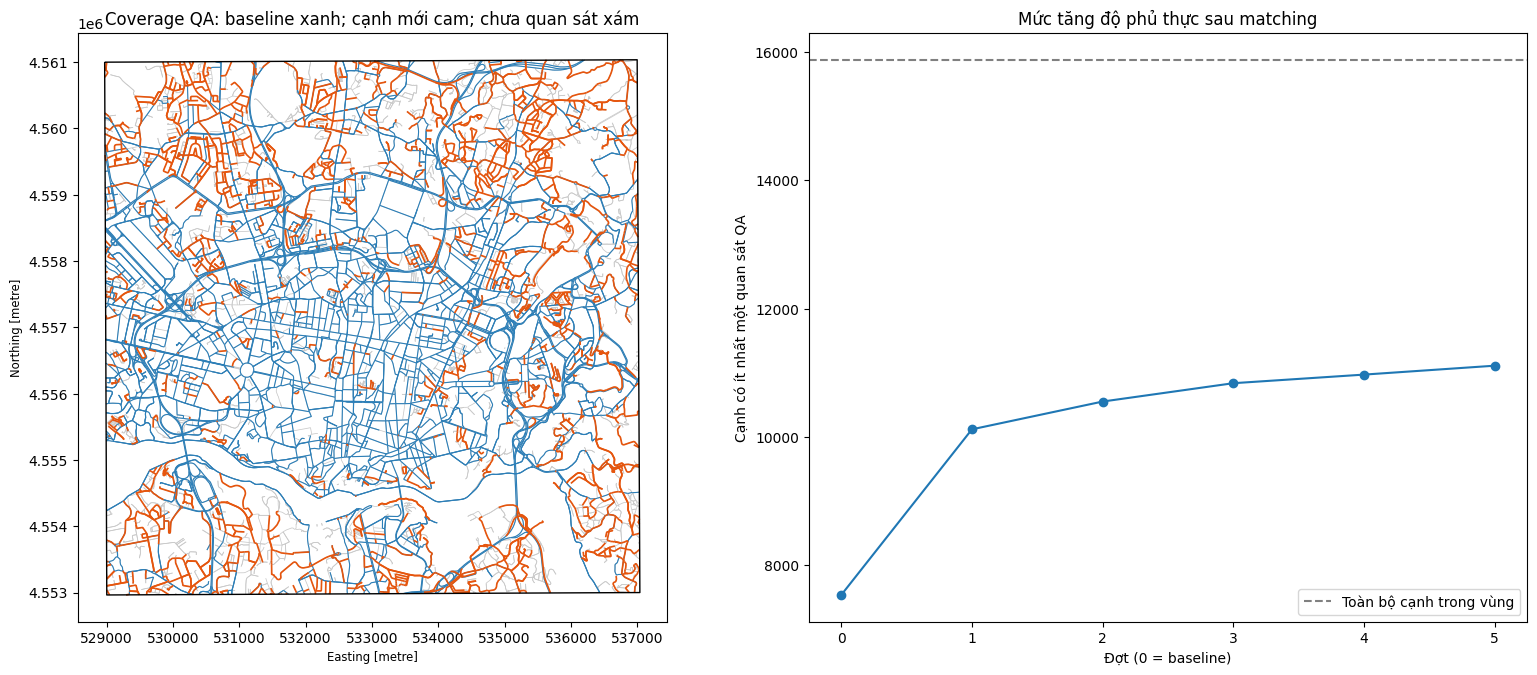

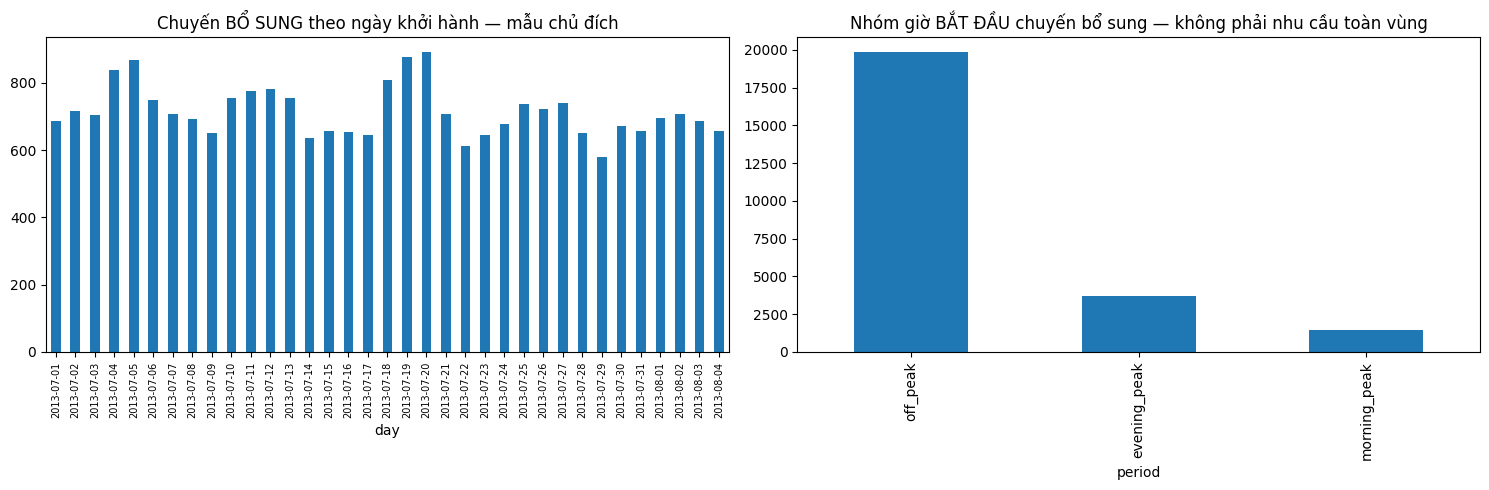

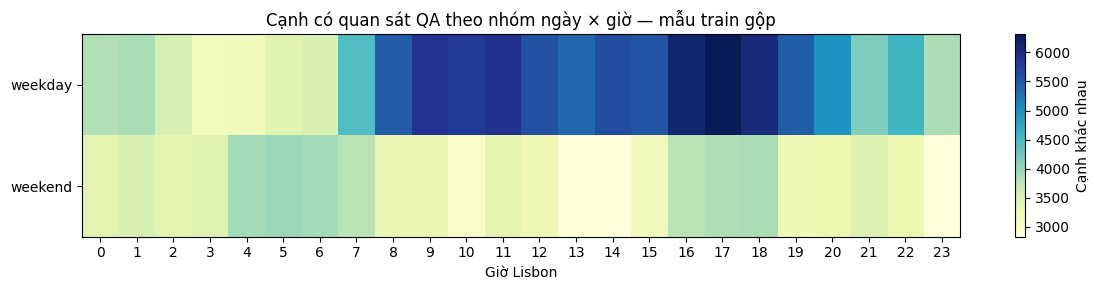

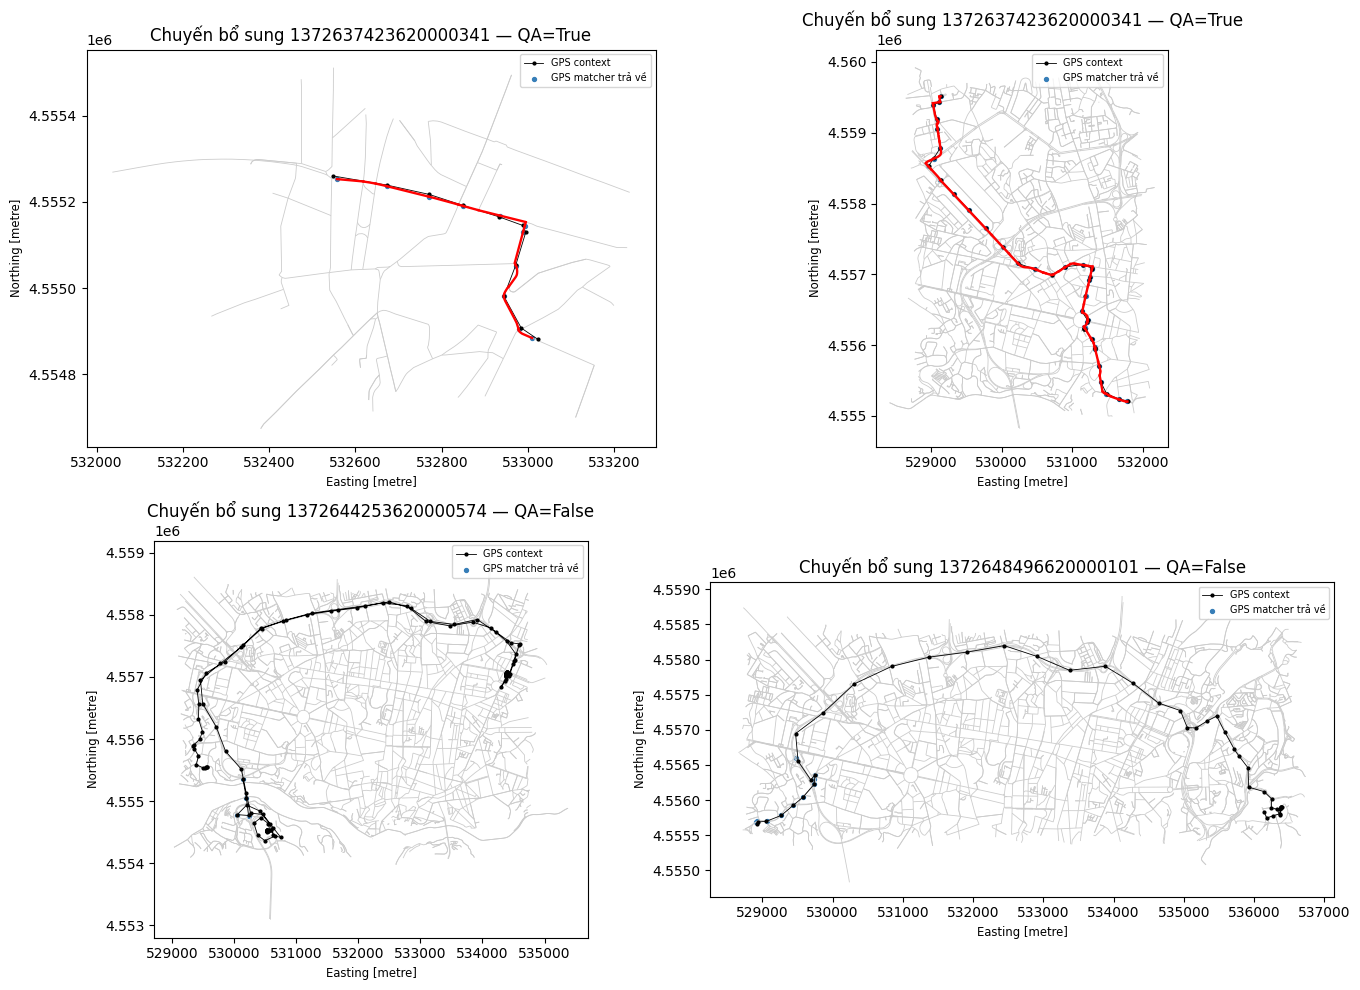

In [9]:
fig,axes=plt.subplots(1,2,figsize=(16,7))
plot_edges=REGION_EDGES.copy()
plot_edges.geometry=shapely.intersection(plot_edges.geometry.to_numpy(),STUDY_POLYGON)
plot_edges.plot(ax=axes[0],color="#c9c9c9",linewidth=.55)
plot_edges[plot_edges.edge_id.isin(BASE_COVERED)].plot(ax=axes[0],color="#2c7fb8",linewidth=.8)
new_plot=plot_edges[plot_edges.edge_id.isin(OBSERVED-BASE_COVERED)]
if not new_plot.empty:new_plot.plot(ax=axes[0],color="#e6550d",linewidth=1.2)
gpd.GeoSeries([STUDY_POLYGON],crs=CFG["metric_crs"]).boundary.plot(ax=axes[0],color="black",linewidth=1)
axes[0].set_title("Coverage QA: baseline xanh; cạnh mới cam; chưa quan sát xám");axes[0].set_aspect("equal")
counts=[len(BASE_COVERED)]+[r["cumulative_observed_edges"] for r in ROUND_REPORTS]
axes[1].plot(range(len(counts)),counts,"o-")
axes[1].axhline(len(REGION_EDGES),color="gray",linestyle="--",label="Toàn bộ cạnh trong vùng")
axes[1].set(xlabel="Đợt (0 = baseline)",ylabel="Cạnh có ít nhất một quan sát QA",title="Mức tăng độ phủ thực sau matching")
axes[1].legend();save_figure("01_incremental_edge_coverage")
fig,axes=plt.subplots(1,2,figsize=(15,5))
if not NEW_SELECTED.empty:
    NEW_SELECTED.groupby("day").size().plot.bar(ax=axes[0]);axes[0].tick_params(axis="x",labelsize=7)
    NEW_SELECTED.period.value_counts().plot.bar(ax=axes[1])
axes[0].set_title("Chuyến BỔ SUNG theo ngày khởi hành — mẫu chủ đích")
axes[1].set_title("Nhóm giờ BẮT ĐẦU chuyến bổ sung — không phải nhu cầu toàn vùng")
save_figure("02_additional_sample_distribution")
hourly=EDGE_TIME.groupby(["day_group","slot"]).edge_id.nunique().unstack("slot").reindex(["weekday","weekend"]).reindex(columns=range(24//CFG["time_bin_hours"])).fillna(0)
fig,ax=plt.subplots(figsize=(12,3));im=ax.imshow(hourly,aspect="auto",cmap="YlGnBu")
ax.set(yticks=[0,1],yticklabels=hourly.index,xticks=range(len(hourly.columns)),
    xticklabels=[i*CFG["time_bin_hours"] for i in hourly.columns],xlabel="Giờ Lisbon",title="Cạnh có quan sát QA theo nhóm ngày × giờ — mẫu train gộp")
fig.colorbar(im,ax=ax,label="Cạnh khác nhau");save_figure("03_combined_hourly_coverage")
if NEW_QA_FRAMES and "subs" in globals():
    qa=matches["qa"];example_ids=[]
    for accepted in [True,False]:
        q=qa[qa.analysis_accepted.eq(accepted)].sort_values("subtrajectory_id")
        example_ids.extend(q.head(2).subtrajectory_id.tolist())
    if example_ids:
        sub_lookup={s["subtrajectory_id"]:s for s in subs}
        edge_lookup=EDGES.set_index("edge_id")
        fig,axes=plt.subplots(math.ceil(len(example_ids)/2),2,figsize=(14,5*math.ceil(len(example_ids)/2)),squeeze=False)
        for ax,sid in zip(axes.flat,example_ids):
            raw=pd.DataFrame(sub_lookup[sid]["points"])
            extent=box(raw.x.min()-120,raw.y.min()-120,raw.x.max()+120,raw.y.max()+120)
            EDGES[EDGES.geometry.intersects(extent)].plot(ax=ax,color="#ccc",linewidth=.6)
            ax.plot(raw.x,raw.y,"ko-",markersize=2,linewidth=.6,label="GPS context")
            snapped=matches["points"]
            if not snapped.empty:
                q=snapped[snapped.subtrajectory_id.eq(sid)]
                ax.scatter(q.matched_x,q.matched_y,s=8,color="#377eb8",label="GPS matcher trả về")
            if not matches["parts"].empty:
                for r in matches["parts"][matches["parts"].subtrajectory_id.eq(sid)].itertuples():
                    line=substring(edge_lookup.loc[r.edge_id,"geometry"],r.entry_offset_m,r.exit_offset_m)
                    if isinstance(line,LineString):ax.plot(*line.xy,color="red",linewidth=1.7)
            ax.set_title(f"Chuyến bổ sung {sub_lookup[sid]['trip_id']} — QA={bool(qa.set_index('subtrajectory_id').loc[sid,'analysis_accepted'])}")
            ax.set_aspect("equal");ax.legend(fontsize=7)
        for ax in list(axes.flat)[len(example_ids):]:ax.set_visible(False)
        save_figure("04_additional_matching_examples")

## H. Kiểm chứng cuối và chạy tiếp

- Sửa đường dẫn tại cell A. Restart Kernel → Run All chạy các đợt đã cấu hình và dùng lại cache hợp lệ. Không cần chạy lại notebook baseline.
- Muốn thêm một đợt: tăng `max_rounds` từ 5 lên 6 rồi Run All. Các đợt cũ dùng cache,
  đợt mới chỉ chọn TRIP_ID chưa thử. Đổi max_rounds không đổi cache scan hay matching.
- CSV tập trung trong `outputs/csv/region_coverage_expansion/<run_key>/`.
- Parquet, PNG, JSON trong `outputs/region_coverage_expansion/<run_key>/`.
- `remaining_unobserved_edges` giữ đúng các cạnh còn thiếu; không xóa chúng khỏi graph.
- Kết quả coverage là trên train được chọn chủ đích. Sau khi chốt ngân sách và pipeline,
  validation/test cần lấy độc lập theo thời gian, không chọn dựa trên khả năng làm đẹp coverage/ETA.
- `edge_coverage=1.0` chỉ có nghĩa mọi cạnh có ít nhất một quan sát QA, chưa bảo đảm đủ
  ngày/taxi/giờ để xây profile. Có thể cần gộp giờ hoặc fallback khi train mô hình sau này.
- Phân bổ thời gian theo khoảng cách trong 15 giây là giả định; QA không phải nhãn đúng/sai độc lập.

In [10]:
assert all(file_hash(BASE/name)==digest for name,digest in BASE_HASHES.items()),"Baseline đã bị thay đổi trong quá trình chạy."
assert len(OBSERVED)==metrics["observed_edges"]
assert len(OBSERVED)>=len(BASE_COVERED)
assert len(NEW_SELECTED)==sum(r["selected_additional_trips"] for r in ROUND_REPORTS)
assert COMBINED_PARTS.duration_s.gt(0).all() and COMBINED_PARTS.distance_traversed_m.ge(0).all()
assert not COMBINED_PARTS.duplicated(["subtrajectory_id","interval_id","part_index","region_piece_index"]).any()
verification={"status":"passed","technical_fixtures":len(TESTS),"baseline_files_unchanged":True,
    "trip_ids_disjoint":True,"observed_edges_monotonic":True,"partial_distance_and_time_checks":True,
    "no_fake_coverage":True,"completed_rounds":len(ROUND_REPORTS),"stop_reason":STOP_REASON}
write_json(RUN/"verification.json",verification)
record_stage("verification","complete",verification)
write_json(OUTPUT/"latest_run.json",{"folder":str(RUN),"run_key":RUN_KEY,"stages":STAGES})
display(pd.DataFrame(ROUND_REPORTS))
print("Kết quả thực:",metrics["observed_edges"],"/",metrics["region_edges"],"cạnh;",metrics["edge_coverage"])
print("CSV:",ROOT/CFG["csv_dir"]/"region_coverage_expansion"/RUN_KEY)

[verification] complete: {'status': 'passed', 'technical_fixtures': 11, 'baseline_files_unchanged': True, 'trip_ids_disjoint': True, 'observed_edges_monotonic': True, 'partial_distance_and_time_checks': True, 'no_fake_coverage': True, 'completed_rounds': 5, 'stop_reason': 'configured_round_budget_reached'}


,round,selected_additional_trips,attempted_subtrajectories,qa_accepted_subtrajectories,qa_trips_in_region,new_edges,cumulative_observed_edges,region_edges,edge_coverage,matching_elapsed_s_this_execution,matching_cache_hits,selected_days,selected_taxis,segment_exceptions
0,1,5000,6846,3669,2870,2582,10121,15882,0.637262,46.311202,274,35,423,0
1,2,5000,6176,3520,2974,433,10554,15882,0.664526,25.567924,248,35,424,0
2,3,5000,6076,3462,2984,286,10840,15882,0.682534,27.425164,244,35,425,0
3,4,5000,6002,3515,3039,134,10974,15882,0.690971,1041.795040,0,35,422,0
4,5,5000,5765,3480,3062,139,11113,15882,0.699723,756.021409,0,35,424,0


Kết quả thực: 11113 / 15882 cạnh; 0.6997229568064476
CSV: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\csv\region_coverage_expansion\a3bc4981c0524eb0f19f


## Tài liệu tham khảo

- Yu Zheng, *Trajectory Data Mining: An Overview* (2015), file `Trajectory Data Mining An Overview.pdf`
  trong workspace; phần trajectory preprocessing và map matching. Đã đối chiếu khái niệm
  khớp chuỗi GPS vào road network; ô lưới dùng chọn ứng viên không thay thế HMM.
- `Trajectory_Data_Mining_Porto.pdf`, đề cương 12 trang trong workspace; giữ pipeline
  preprocessing → map matching → QA, bổ sung bước mở rộng mẫu theo coverage và hoãn demo.
- Dataset [Kaggle Porto Taxi / ECML-PKDD 2015](https://www.kaggle.com/competitions/pkdd-15-predict-taxi-service-trajectory-i/data),
  chỉ `train.csv`; không dùng test quỹ đạo dở dang làm nhãn giao thông.
- [pandas](https://pandas.pydata.org/docs/), [NumPy](https://numpy.org/doc/),
  [PyArrow / Parquet](https://arrow.apache.org/docs/python/parquet.html),
  [GeoPandas](https://geopandas.org/en/stable/docs.html), [Shapely STRtree](https://shapely.readthedocs.io/en/stable/strtree.html),
  [pyproj](https://pyproj4.github.io/pyproj/stable/), [OSMnx](https://osmnx.readthedocs.io/en/stable/),
  [NetworkX](https://networkx.org/documentation/stable/),
  [Leuven Map Matching](https://leuvenmapmatching.readthedocs.io/en/latest/),
  [Rtree](https://rtree.readthedocs.io/en/latest/), [joblib](https://joblib.readthedocs.io/en/stable/),
  [Matplotlib](https://matplotlib.org/stable/), [psutil](https://psutil.readthedocs.io/en/latest/),
  [Python sqlite3](https://docs.python.org/3/library/sqlite3.html).
  Phiên bản thực sự sử dụng được lưu tại `environment.json`.